# 12 - Predict Treatment Response

First run 12a, 12b, 12c

This notebook creates treatment response classifiers from gene expression

# 0. Setup

## Imports

In [193]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedGroupKFold, GridSearchCV, StratifiedKFold, train_test_split, GroupShuffleSplit
from sklearn.metrics import roc_auc_score #, average_precision_score, ConfusionMatrixDisplay, confusion_matrix, RocCurveDisplay, roc_curve
from sklearn.metrics import f1_score, recall_score,precision_score,accuracy_score
from sklearn.pipeline import Pipeline
import os
import glob

In [194]:
import seaborn as sns
import matplotlib.pyplot as plt
import joblib #to save models

In [ ]:
from utils import set_seed, load_features_from_csv
from gene_model import GeneModelStore
from utils import compare_patient_preds, majority_vote_binary #, hard_majority
from utils import patient_level_predictions, patient_level_metrics
from visualize import display_optimal_threshold, plot_classification_results
from visualize import display_preds_subplots, display_pooled_patch_distrib
from visualize import display_spatial_expression_on_axis

In [196]:
from datetime import date

# Returns the current local date
today = date.today()
print("Today date is: ", today)

Today date is:  2026-03-02


## Utility Functions

In [197]:
def z(col): return (col - col.mean()) / (col.std(ddof=0) + 1e-8)

In [198]:
def extract_ids(filename):
    import re

    # This regex finds "LEAP" followed by digits, then later "Slide" (with an optional hyphen, underscore, or space) and digits.
    pattern = r'(Slide \d+).*?.ndpi'
    match = re.search(pattern, filename, re.IGNORECASE)
    if match:
        sname = match.group(0)
        #print(sname)
    else:
        sname = None
        #print("no match")

    pattern = r'Slide \d+'
    match = re.search(pattern, filename, re.IGNORECASE)
    if match:
        snum = match.group(0)
        #print(snum)
    else:
        snum = None
        #print("no slide num")

    pattern = r'LEAP\d+'
    match = re.search(pattern, filename, re.IGNORECASE)
    if match:
        leap = match.group(0)
        #print(leap)
    else:
        leap = None
        #print("no LEAPID")
    
    return sname, snum, leap

In [199]:
def pick_correct_proba_column(model, X, y_true):
    """
    Safeguard against label-order confusion:
    returns proba for class 1 as defined in y_true (assumes y_true is 0/1).
    """
    proba = model.predict_proba(X)
    classes = model.classes_
    # find column corresponding to class 1
    col_1 = np.where(classes == 1)[0]
    if len(col_1) != 1:
        raise ValueError(f"Could not find class 1 in model.classes_: {classes}")
    return proba[:, col_1[0]]

In [200]:
def sample_per_leap_id(df, n_per_id, random_state=42):

    return (
        df
        .groupby('LEAP_ID', group_keys=False)
        .apply(
            lambda g: g.sample(
                n=min(len(g), int(n_per_id.get(g.name, 0))),
                random_state=random_state
            )
        )
    )


In [201]:
def display_metrics(y_test, y_probs, thresh=0.5, model_name='unknown', description=''):
    y_preds = (y_probs>thresh).astype(int)
    # print(f"AUC:       {roc_auc_score(y_test, y_probs):.2f}")
    # print(f"Avg Prec:  {average_precision_score(y_test, y_probs):.2f}")
    # print("with Threshold: ",thresh)

    # print(f"\tF1:        {f1_score(y_test, y_preds):.2f}")
    # print(f"\tRecall:    {recall_score(y_test, y_preds):.2f}")
    # print(f"\tPrecision: {precision_score(y_test, y_preds):.2f}")
    # print(f"\tAccuracy:  {accuracy_score(y_test, y_preds):.2f}")

    
    return pd.DataFrame([{
        'Model': model_name,
        'Description': description,
        'Threshold': thresh,
        'AUC': roc_auc_score(y_test, y_probs),
        'F1': f1_score(y_test, y_preds),
        'Recall': recall_score(y_test, y_preds),
        'Precision': precision_score(y_test, y_preds),
        'Accuracy': accuracy_score(y_test, y_preds)
    }])


In [202]:
def display_multiple_genes(leap, heimg, limits, genes_to_show=['MKI67_PanCK'], title=""):
    #print(leap)
    #print(genes_to_show)
    xlims = [lim[0]/4 for lim in limits[leap]]
    ylims = [lim[1]/4 for lim in limits[leap]]
    xlims = (xlims[0], xlims[1])
    ylims = (ylims[0], ylims[1])
    meta_tmp = test_metadata[test_metadata['LEAP_ID'] ==leap]
    expr_tmp = expr.loc[meta_tmp.index]
    
    fig, axes = plt.subplots(1,len(genes_to_show), figsize=(12, 4),constrained_layout=True)
    if len(genes_to_show) == 1:
        axes = [axes]  # make iterable
    #axes = axes.flatten()
    for ax, gene in zip(axes, genes_to_show):
        #print(gene)
        ax = display_spatial_expression_on_axis(gene,heimg,meta_tmp,expr_tmp.T, xlim=xlims, ylim=ylims, ax=ax)

    plt.suptitle(title)
    plt.show()

## Set Parameters

for overlay/viz

In [ ]:
RUN_INFERENCE = False
ROBUST_GENES_ONLY = True
DROP_PROBLEM_TISSUE = True
APPLY_CALIB = False
USE_Z_SCORES = False
TUNE_C = True
APPLY_SCALING = True
USE_GSS = False

DROP_LEAPS = {'LEAP057','LEAP058'} # Fresh-Frozen tissue that needs to be removed from analysis

In [ ]:
ext_root_path = 'F:/01-data/LEAP' 
root_path = "../data"
rawdata_path = os.path.join(root_path,'01-raw')
output_path = os.path.join(root_path,'04-results_test')
tr_path = os.path.join(root_path,'06-treatment_response')
feature_path = os.path.join(tr_path,'img_feats')

feat_file = 'imgfeats_traintest.csv'

In [205]:
flags = {
    "robust": ROBUST_GENES_ONLY,
    "droptissue": DROP_PROBLEM_TISSUE,
    "calib": APPLY_CALIB,
    "zscores": USE_Z_SCORES,
    "tunec": TUNE_C,
}

suffix = "".join(f"_{name}" for name, enabled in flags.items() if enabled)
experiment_name = f"run_{today}{suffix}"
exp_path = os.path.join(tr_path, 'metrics',experiment_name)
print(exp_path)
os.makedirs(exp_path, exist_ok=True)

C:/Users/hooll/Dropbox/19 PostGrad/00 CB Lab/01 projects/06 MultiModal/data\06-treatment_response\metrics\run_2026-03-02_robust_droptissue_calib_tunec


In [206]:
joblib.dump(flags, os.path.join(exp_path,"flags.joblib"))

['C:/Users/hooll/Dropbox/19 PostGrad/00 CB Lab/01 projects/06 MultiModal/data\\06-treatment_response\\metrics\\run_2026-03-02_robust_droptissue_calib_tunec\\flags.joblib']

In [207]:
# from openslide import OpenSlide
# import matplotlib.patches as patches
# from LEAPdata import get_slide_id
# import openslide
# from PIL import Image
import PIL

WSI_PATH = os.path.join(ext_root_path,'WSI','0-original')
annotation_path = os.path.join(ext_root_path,'WSI','4-TreatmentResponse')
img_path = os.path.join(ext_root_path,'WSI','2-aligned','10x','cleaned')

# Increase the image pixel limit
PIL.Image.MAX_IMAGE_PIXELS = None  # Removes the limit entirely
SUPTITLESIZE=18
TITLESIZE=16
LABELSIZE=14
NOTESIZE=10

OME_LEVEL = 2 # should be level 1 but haven't extracted at 20x yet
DOWNSAMPLE = 2**OME_LEVEL

In [208]:
probs_dict = {}

# 1. Load data

## Image Features

In [209]:
image_names, feature_matrix = load_features_from_csv(os.path.join(feature_path,feat_file))

In [210]:
feature_matrix_df = pd.DataFrame(feature_matrix, index=image_names)
assert feature_matrix.shape[0] == len(image_names)
assert feature_matrix_df.shape[0] == feature_matrix.shape[0]

## Metadata

In [211]:
patch_metadata = pd.DataFrame([x.replace('.png','').split('_') for x in image_names],
                                columns=['Slide', 'LEAP_ID', 'x', 'y'],
                                index=image_names)

In [212]:
sample_metadata = pd.read_csv(os.path.join(rawdata_path,'metadata',"patient_metadata.csv"), index_col=0)
# add response and age to patches
patch_metadata['Response'] = patch_metadata['LEAP_ID'].map(sample_metadata['Response'])
patch_metadata["age"] = patch_metadata["LEAP_ID"].map(sample_metadata["Age"])
patch_metadata["age"].isna().any()

False

In [213]:
patch_metadata['Response'].unique()

array(['Responder', 'Non-Responder'], dtype=object)

## Summarise Data

In [214]:
sample_metadata[['Response','ECT_Carbo', 'NACT_Group']]

,Response,ECT_Carbo,NACT_Group
LEAP_ID,,,
LEAP058,Non-Responder,NO,FEC
LEAP057,Non-Responder,NO,FEC
LEAP021,Responder,YES,EC-T
LEAP024,Non-Responder,YES,EC-T
LEAP041,Responder,YES,EC-T
LEAP019,Non-Responder,YES,EC-T
LEAP077,Responder,YES,EC-T-carbo
LEAP104,Responder,YES,EC-T-carbo
LEAP090,Responder,YES,EC-T-carbo


In [215]:
patch_metadata.groupby(['Response','LEAP_ID']).count()


Slide     x     y   age
Response      LEAP_ID                         
Non-Responder LEAP001     43    43    43    43
              LEAP003     68    68    68    68
              LEAP019    353   353   353   353
              LEAP024    292   292   292   292
              LEAP044    312   312   312   312
              LEAP057     79    79    79    79
              LEAP058     80    80    80    80
              LEAP114   1113  1113  1113  1113
              LEAP140    108   108   108   108
              LEAP152    185   185   185   185
Responder     LEAP021    340   340   340   340
              LEAP041    792   792   792   792
              LEAP077    396   396   396   396
              LEAP090    162   162   162   162
              LEAP104    196   196   196   196
              LEAP116    138   138   138   138

In [216]:
patch_metadata.groupby(['Response']).count()

,Slide,LEAP_ID,x,y,age
Response,,,,,
Non-Responder,2633,2633,2633,2633,2633
Responder,2024,2024,2024,2024,2024


In [217]:
image_names

['SLIDE10_LEAP021_19400_43174.png',
 'SLIDE10_LEAP021_20296_34214.png',
 'SLIDE10_LEAP021_20296_35110.png',
 'SLIDE10_LEAP021_20296_36006.png',
 'SLIDE10_LEAP021_20296_36902.png',
 'SLIDE10_LEAP021_20296_42278.png',
 'SLIDE10_LEAP021_20296_43174.png',
 'SLIDE10_LEAP021_21192_30630.png',
 'SLIDE10_LEAP021_21192_33318.png',
 'SLIDE10_LEAP021_21192_34214.png',
 'SLIDE10_LEAP021_21192_35110.png',
 'SLIDE10_LEAP021_21192_36006.png',
 'SLIDE10_LEAP021_21192_38694.png',
 'SLIDE10_LEAP021_21192_42278.png',
 'SLIDE10_LEAP021_21192_43174.png',
 'SLIDE11_LEAP024_41774_16209.png',
 'SLIDE10_LEAP021_22088_29734.png',
 'SLIDE10_LEAP021_22088_36902.png',
 'SLIDE10_LEAP021_22088_38694.png',
 'SLIDE10_LEAP021_22984_38694.png',
 'SLIDE10_LEAP021_22984_39590.png',
 'SLIDE10_LEAP021_22984_40486.png',
 'SLIDE10_LEAP021_22984_41382.png',
 'SLIDE10_LEAP021_23880_37798.png',
 'SLIDE10_LEAP021_23880_38694.png',
 'SLIDE10_LEAP021_23880_39590.png',
 'SLIDE10_LEAP021_23880_40486.png',
 'SLIDE10_LEAP021_23880_4586

# 2. Infer gene expression for image features

Currently just loading predicted expression but this should be loading the model, loading features and predicting the expression

## 2.1 Load models

In [218]:
if RUN_INFERENCE:
    models_folder = 'calibrated'
    store_cd45 = GeneModelStore(model_dir=os.path.join(output_path,'trained_models',models_folder,'cd45'))
    store_cd45.load_all()  # or store.load_selected(["TP53", "BRCA1"])
    len(store_cd45.genes)

    store_panck = GeneModelStore(model_dir=os.path.join(output_path,'trained_models',models_folder,'panck'))
    store_panck.load_all()
    len(store_panck.genes)


## 2.2 Run Inference

In [219]:
# ## predict
if RUN_INFERENCE:
    print("running inference")
    gene_preds_cd45 = store_cd45.predict_many(None, feature_matrix, row_names=image_names, apply_calibration=APPLY_CALIB)
    gene_preds_panck = store_panck.predict_many(None, feature_matrix, row_names=image_names, apply_calibration=APPLY_CALIB)
    expr = pd.concat([
        gene_preds_cd45.add_suffix("_CD45"),
        gene_preds_panck.add_suffix("_PanCK")
    ], axis=1)
    gene_preds_cd45.to_csv(f"gene_preds_cd45_{today}.csv")
    gene_preds_panck.to_csv(f"gene_preds_panck_{today}.csv")
    expr.to_csv(os.path.join(root_path,'06-treatment_response',f"inferred_expr_{today}.csv"))


In [220]:
if not RUN_INFERENCE:
    print("loading from csv")
    if APPLY_CALIB:
        #gene_preds_cd45 = pd.read_csv(os.path.join(root_path,'04-results_test','predicted_expression','preds_calibrated_CD45_combined_SVM.csv'), index_col=0)
        #gene_preds_panck = pd.read_csv(os.path.join(root_path,'04-results_test','predicted_expression','preds_calibrated_PanCK_combined_SVM.csv'), index_col=0)
        # gene_preds_cd45 = pd.read_csv("gene_preds_cd45_{today}.csv", index_col=0)
        # gene_preds_panck = pd.read_csv("gene_preds_panck_{today}.csv", index_col=0)
        # expr = pd.read_csv(os.path.join(root_path,'06-treatment_response',"inferred_expr_2026-02-06.csv"), index_col=0)
        gene_preds_cd45 =   pd.read_csv(os.path.join(tr_path,'inferred_expression',"expression_cd45_calibrated_imgfeats_traintest.csv"), index_col=0)
        gene_preds_panck =  pd.read_csv(os.path.join(tr_path,'inferred_expression',"expression_panck_calibrated_imgfeats_traintest.csv"), index_col=0)
        expr =              pd.read_csv(os.path.join(tr_path,'inferred_expression',"expression_all_calibrated_imgfeats_traintest.csv"), index_col=0)
    else:
        gene_preds_cd45 =   pd.read_csv(os.path.join(tr_path,'inferred_expression',"expression_cd45_uncalibrated_imgfeats_traintest.csv"), index_col=0)
        gene_preds_panck =  pd.read_csv(os.path.join(tr_path,'inferred_expression',"expression_panck_uncalibrated_imgfeats_traintest.csv"), index_col=0)
        expr =              pd.read_csv(os.path.join(tr_path,'inferred_expression',"expression_all_uncalibrated_imgfeats_traintest.csv"), index_col=0)

loading from csv


In [221]:
assert gene_preds_cd45.shape[0]==expr.shape[0]
assert gene_preds_panck.shape[0]==expr.shape[0]

In [222]:
# joblib.dump(
#     list(gene_preds_cd45.columns),
#     os.path.join(root_path,'06-treatment_response','cd45_genelist_full.joblib')
#     )
# joblib.dump(
#     list(gene_preds_panck.columns),
#     os.path.join(root_path,'06-treatment_response','panck_genelist_full.joblib')
#     )

Drop problem cores

In [223]:
if DROP_PROBLEM_TISSUE:
    
    drop_ind = patch_metadata[patch_metadata['LEAP_ID'].isin(DROP_LEAPS)].index
    print(drop_ind)
    expr = expr.drop(index=drop_ind)
    patch_metadata = patch_metadata.drop(index=drop_ind)
    sample_metadata = sample_metadata.drop(index=DROP_LEAPS)
    image_names = [x for x in image_names if x not in set(drop_ind)]
    feature_matrix_df = feature_matrix_df.drop(index=drop_ind)

Index(['SLIDE25_LEAP057_3660_48487.png', 'SLIDE25_LEAP057_3660_51175.png',
       'SLIDE25_LEAP057_3660_49383.png', 'SLIDE25_LEAP057_3660_50279.png',
       'SLIDE25_LEAP057_4556_47591.png', 'SLIDE25_LEAP057_4556_50279.png',
       'SLIDE25_LEAP057_4556_48487.png', 'SLIDE25_LEAP057_4556_49383.png',
       'SLIDE25_LEAP057_4556_51175.png', 'SLIDE25_LEAP057_5452_49383.png',
       ...
       'SLIDE26_LEAP058_16641_8831.png', 'SLIDE26_LEAP058_17537_6143.png',
       'SLIDE26_LEAP058_17537_7039.png', 'SLIDE26_LEAP058_17537_7935.png',
       'SLIDE26_LEAP058_18433_6143.png', 'SLIDE26_LEAP058_18433_7039.png',
       'SLIDE26_LEAP058_18433_7935.png', 'SLIDE26_LEAP058_19329_7039.png',
       'SLIDE26_LEAP058_19329_7935.png', 'SLIDE26_LEAP058_19329_8831.png'],
      dtype='object', length=159)


In [224]:
patch_metadata['LEAP_ID'].unique()

array(['LEAP021', 'LEAP024', 'LEAP041', 'LEAP019', 'LEAP152', 'LEAP001',
       'LEAP044', 'LEAP077', 'LEAP090', 'LEAP104', 'LEAP114', 'LEAP116',
       'LEAP140', 'LEAP003'], dtype=object)

In [225]:
patch_metadata['LEAP_ID'].value_counts()

LEAP_ID
LEAP114    1113
LEAP041     792
LEAP077     396
LEAP019     353
LEAP021     340
LEAP044     312
LEAP024     292
LEAP104     196
LEAP152     185
LEAP090     162
LEAP116     138
LEAP140     108
LEAP003      68
LEAP001      43
Name: count, dtype: int64

In [226]:
assert (patch_metadata.shape[0]==expr.shape[0])
assert (len(image_names)==expr.shape[0])

## 2.3 Compute Z scores per gene

not currently using the z scores - should I be using this instead of the expr?

In [227]:
if USE_Z_SCORES:
    expr = expr.apply(z, axis=0)   # z-score each gene across patients


# 3. Treatment Response Models

In [228]:
metrics = []

## Specify single pipeline for all models

In [229]:
pipe = Pipeline([
    #("scaler", StandardScaler()),
    ("clf", LogisticRegression(
        penalty="l1",
        solver="saga",
        class_weight="balanced",
        max_iter=5000,
        random_state=77
    ))
])
cv = StratifiedGroupKFold(n_splits=3, shuffle=True, random_state=77)

In [230]:
if TUNE_C:
    param_grid = {"clf__C": [0.1, 1, 5, 10, 20, 100]} #np.logspace(-3, 2, 10)}
else:
    param_grid = {"clf__C": [1]} 


y = Response ('labels' df)

X = gene expression ('expr' or 'Z')

In [231]:
if ROBUST_GENES_ONLY:
    robust_genes = joblib.load(os.path.join(root_path, '05-pathway_analysis','genes','robust_genes.joblib'))
    expr = expr[robust_genes]

In [232]:
patch_metadata = patch_metadata.sort_index()
expr = expr.sort_index()
assert (patch_metadata.index == expr.index).all()

In [233]:
labels = (patch_metadata['Response'] == 'Responder').astype(int)
assert (labels.index == expr.index).all()

In [234]:
patch_metadata['Response'].value_counts()

Response
Non-Responder    2474
Responder        2024
Name: count, dtype: int64

In [235]:
print(f"{2024/(2633+2024)*100:.2f}%")

43.46%


In [236]:
joblib.dump(
    expr.columns.to_list(),
    os.path.join(exp_path,"feature_names.joblib")
)

['C:/Users/hooll/Dropbox/19 PostGrad/00 CB Lab/01 projects/06 MultiModal/data\\06-treatment_response\\metrics\\run_2026-03-02_robust_droptissue_calib_tunec\\feature_names.joblib']



## Sample data
Split predictions into train and test

need to modify this to keep leap ids together

In [237]:
set_seed(77)

In [238]:
y = labels.to_numpy()
X = expr.to_numpy()

In [239]:
sample_metadata.columns

Index(['Patient_ID', 'Slide.Number', 'Format', 'ECT_Carbo', 'NACT_Group',
       'Response', 'Age_Cat', 'Ethnicity', 'BRCA1', 'Age', 'EthnicGroup',
       'DistRecTime', 'RCB volume', 'pCR group'],
      dtype='object')

In [240]:
patch_counts = (
    patch_metadata
    .groupby("LEAP_ID")
    .size()
    .rename("n_patches")
)
if 'n_patches' not in sample_metadata.columns:
    sample_metadata = sample_metadata.join(patch_counts)
sample_metadata.head()

,Patient_ID,Slide.Number,Format,ECT_Carbo,NACT_Group,Response,Age_Cat,Ethnicity,BRCA1,Age,EthnicGroup,DistRecTime,RCB volume,pCR group,n_patches
LEAP_ID,,,,,,,,,,,,,,,
LEAP021,GST23703,10,FFPE,YES,EC-T,Responder,< 50,Black,Wild Type,47.731691,Black,NaN,0.000,pCR,340
LEAP024,GST26322,11,FFPE,YES,EC-T,Non-Responder,< 50,Black,NaN,47.731691,Black,1.984942,2.403,II,292
LEAP041,GST26965,19,FFPE,YES,EC-T,Responder,< 50,White,Wild Type,37.642710,White,NaN,0.000,pCR,792
LEAP019,GST27131,9,FFPE,YES,EC-T,Non-Responder,< 50,White,NaN,48.123203,White,NaN,2.672,II,353
LEAP077,GST41084,33,FFPE,YES,EC-T-carbo,Responder,< 50,White,Wild Type,35.578371,White,NaN,0.000,pCR,396


In [241]:
sample_metadata.sort_values('n_patches', ascending=False)[['Response', 'Age','n_patches']]

,Response,Age,n_patches
LEAP_ID,,,
LEAP114,Non-Responder,57.478439,1113
LEAP041,Responder,37.642710,792
LEAP077,Responder,35.578371,396
LEAP019,Non-Responder,48.123203,353
LEAP021,Responder,47.731691,340
LEAP044,Non-Responder,46.762491,312
LEAP024,Non-Responder,47.731691,292
LEAP104,Responder,61.084189,196
LEAP152,Non-Responder,74.989733,185


In [242]:
sample_metadata.groupby('Response')[[ 'n_patches']].describe(percentiles=[])

n_patches                                              
                  count        mean         std    min    50%     max
Response                                                             
Non-Responder       8.0  309.250000  345.018322   43.0  238.5  1113.0
Responder           6.0  337.333333  245.202501  138.0  268.0   792.0

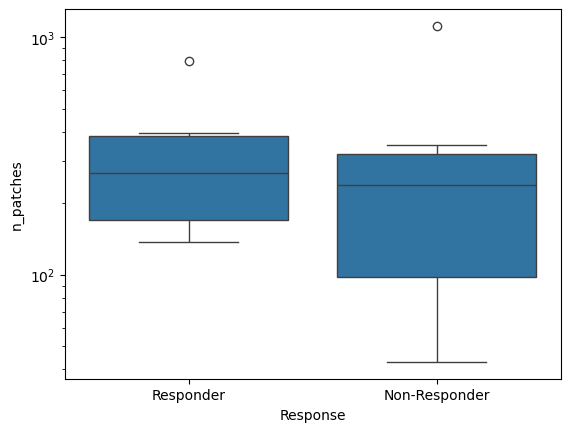

In [243]:
sns.boxplot(
    data=sample_metadata,
    x="Response",
    y="n_patches"
)
plt.yscale("log")
plt.show()

### Rules based sampling
*“We subsampled 2589 training patches (target maximum < 3000) from 9–12 tissue samples, limiting each tissue to at most 400 patches. Patch quotas were allocated approximately evenly across tissues and adjusted to respect tissue-specific availability.”*

Training:
- N < 3000 patches
- From K ∈ [9, 12] LEAP_IDs
- With ≤ 400 patches per LEAP_ID

Testing:
 - all patches from all LEAP_IDs not used for training

**Step 1** — Select LEAP_IDs (patient-level control)

Do not let patch counts decide this implicitly.

Options:

- Random (with seed)

- Stratified (e.g. responders/non-responders)

- “largest available first” to avoid tiny samples
Randomly select K LEAP_IDs from those with ≥ X patches, where X ≈ 150–200.

In [244]:
len(patch_metadata['LEAP_ID'].unique())

14

In [245]:
rng = np.random.default_rng(42)

TOTAL_PATCHES = 2800
MIN_LEAPS = 10
MAX_LEAPS = 12
MAX_PER_LEAP = 400
MIN_AVAILABLE = 100  # safety threshold

# --- count available patches per LEAP ---
leap_counts = (
    patch_metadata
    .groupby("LEAP_ID")
    .size()
    .rename("n_available")
)
leap_info = (
    leap_counts.to_frame()
    .join(sample_metadata[["Response"]], how="inner")
)

# --- eligible LEAPs ---
#eligible = leap_counts[leap_counts >= MIN_AVAILABLE]

eligible = leap_info[leap_info["n_available"] >= MIN_AVAILABLE]

resp_pool = eligible.query("Response == 'Responder'").index.to_numpy()
nonresp_pool = eligible.query("Response == 'Non-Responder'").index.to_numpy()

# --- choose number of LEAPs ---
K = rng.integers(MIN_LEAPS, MAX_LEAPS + 1)

# selected_leaps = rng.choice(
#     eligible.index,
#     size=K,
#     replace=False
# )

# Aim for class balance at LEAP level
k_resp = K // 2
k_nonresp = K - k_resp

selected_resp = rng.choice(resp_pool, size=k_resp, replace=False)
selected_nonresp = rng.choice(nonresp_pool, size=k_nonresp, replace=False)

selected_leaps = np.concatenate([selected_resp, selected_nonresp])

counts = leap_counts.loc[selected_leaps]



In [246]:
counts

LEAP_ID
LEAP077     396
LEAP104     196
LEAP116     138
LEAP090     162
LEAP041     792
LEAP152     185
LEAP044     312
LEAP024     292
LEAP114    1113
LEAP140     108
Name: n_available, dtype: int64

**Step 2** Allocate patch quotas 
Start with an equal target:

1. target_per_leap = floor(3000 / K)
2. Cap at 400
3. Respect available patches
4. Redistribute leftovers iteratively

This avoids:
- Overusing massive slides
- Underusing smaller ones
- Silent bias

In [247]:

# --- initial allocation ---
base = TOTAL_PATCHES // K

alloc = pd.Series(
    np.minimum(base, MAX_PER_LEAP),
    index=selected_leaps,
    name="n_target"
)

# respect availability
alloc = np.minimum(alloc, counts)
cap = np.minimum(counts, MAX_PER_LEAP)

# --- redistribute remaining patches ---
remaining = TOTAL_PATCHES - alloc.sum()

while remaining > 0:
    room = cap - alloc

    candidates = room[room > 0]
    if candidates.empty:
        break
        # raise ValueError(
        #     f"Cannot allocate {TOTAL_PATCHES} patches with cap {MAX_PER_LEAP} "
        #     f"across chosen LEAPs. Max possible is {int(cap.sum())}."
        # )

    # add = candidates.index[
    #     rng.integers(0, len(candidates))
    # ]

    add = rng.choice(candidates.index)

    alloc.loc[add] += 1
    remaining -= 1


If you ever want weighted redistribution (e.g. favour LEAPs with more remaining room):
weights = room.loc[candidates.index]
weights = weights / weights.sum()

add = rng.choice(candidates.index, p=weights)

check we have met all rules

In [248]:
print(alloc.sum())
alloc

2589


LEAP077    396
LEAP104    196
LEAP116    138
LEAP090    162
LEAP041    400
LEAP152    185
LEAP044    312
LEAP024    292
LEAP114    400
LEAP140    108
dtype: int64

In [249]:
assert alloc.sum() <= TOTAL_PATCHES
assert alloc.max() <= MAX_PER_LEAP
assert MIN_LEAPS <= alloc.size <= MAX_LEAPS

**Step 3** Sample Patches

In [250]:
# --- sample patches ---
sampled_indices = []

for leap_id, n in alloc.items():
    idx = patch_metadata.index[patch_metadata["LEAP_ID"] == leap_id ]
    sampled_indices.extend( rng.choice(idx, size=n, replace=False) )

train_patches = patch_metadata.loc[sampled_indices]

Select Test patches

In [251]:
train_leaps = set(train_patches["LEAP_ID"].unique())

test_patches = patch_metadata[
    ~patch_metadata["LEAP_ID"].isin(train_leaps)
].copy()

test_leaps = set(test_patches["LEAP_ID"].unique())


In [252]:
train_leaps

{'LEAP024',
 'LEAP041',
 'LEAP044',
 'LEAP077',
 'LEAP090',
 'LEAP104',
 'LEAP114',
 'LEAP116',
 'LEAP140',
 'LEAP152'}

In [253]:
test_leaps

{'LEAP001', 'LEAP003', 'LEAP019', 'LEAP021'}

define X/y data

In [254]:
train_idx = train_patches.index
test_idx  = test_patches.index

X_train = X.loc[train_idx] if hasattr(X, "loc") else X[patch_metadata.index.get_indexer(train_idx)]
y_train = y.loc[train_idx] if hasattr(y, "loc") else y[patch_metadata.index.get_indexer(train_idx)]

X_test  = X.loc[test_idx]  if hasattr(X, "loc") else X[patch_metadata.index.get_indexer(test_idx)]
y_test  = y.loc[test_idx]  if hasattr(y, "loc") else y[patch_metadata.index.get_indexer(test_idx)]

In [255]:
print(f"{X_train.shape[0]} train patches | {X_test.shape[0]} test patches")

2589 train patches | 804 test patches


In [256]:
# groups aligned to X_train rows
if train_idx.dtype == 'int64':
    groups_train = patch_metadata['LEAP_ID'].iloc[train_idx].to_numpy()
else:
    groups_train = patch_metadata['LEAP_ID'].loc[train_idx].to_numpy()


## Reuse the initial GSS sampling

In [257]:

gss = GroupShuffleSplit(
    n_splits=1,          # just one train/test split
    test_size=0.2,       # 20 % of the groups → test set
    random_state=1  )   ### random_state=1 was the original i used

train_idx_gss, test_idx_gss = next( gss.split(X,              # X
                y=None,                 # y (optional)
                groups=patch_metadata['LEAP_ID']))  # the grouping key

print(np.unique(y[train_idx_gss], return_counts=True))
print(np.unique(y[test_idx_gss], return_counts=True))

"""Check LEAP_IDs are only in either train or test - should pass the assertion with no output"""
train_LEAPIDs_gss = set(patch_metadata['LEAP_ID'].iloc[train_idx_gss].unique())
test_LEAPIDs_gss = set(patch_metadata['LEAP_ID'].iloc[test_idx_gss].unique())
assert train_LEAPIDs_gss.isdisjoint(test_LEAPIDs_gss), (
    f"Data-leakage: these LEAP_IDs are in both splits → "
    f"{train_LEAPIDs_gss & test_LEAPIDs_gss}"
)

print(test_LEAPIDs_gss)

(array([0, 1]), array([2162, 1288], dtype=int64))
(array([0, 1]), array([312, 736], dtype=int64))
{'LEAP077', 'LEAP044', 'LEAP021'}


In [258]:
if USE_GSS:
    train_idx_gss
    if train_idx_gss.dtype == 'int64':
        groups_train_gss = patch_metadata['LEAP_ID'].iloc[train_idx_gss].to_numpy()
    else:
        groups_train_gss = patch_metadata['LEAP_ID'].loc[train_idx_gss].to_numpy()
    len(groups_train_gss)

In [259]:
if USE_GSS:
    X_train = X[train_idx_gss]
    y_train = y[train_idx_gss]

    X_test  = X[test_idx_gss]
    y_test = y[test_idx_gss]

    groups_train = groups_train_gss

In [260]:
X_train.shape

(2589, 147)

In [261]:
y_train.sum()

1292

In [262]:
X_test.shape

(804, 147)

## A) TR Model - Inferred Expression

### A1 Train

In [263]:
gs = GridSearchCV(
    pipe,
    param_grid=param_grid,
    scoring="roc_auc",
    cv=cv,
    n_jobs=-1,
    refit=True
)
set_seed(77) 
gs.fit(X_train, y_train, groups=groups_train)

print("Best params:", gs.best_params_)
print("Best CV AUC:", gs.best_score_)

best_model = gs.best_estimator_

Best params: {'clf__C': 0.1}
Best CV AUC: 0.6981422720720208


In [264]:
gs.cv_results_

{'mean_fit_time': array([10.70662816, 28.40651727, 33.20989593, 32.19675287, 33.02937182,
        30.73230735]),
 'std_fit_time': array([2.55257625, 2.44702551, 2.35078415, 3.09427731, 2.99337472,
        2.94640703]),
 'mean_score_time': array([0.00630331, 0.00402395, 0.00185251, 0.00453854, 0.00510065,
        0.00488257]),
 'std_score_time': array([0.00395218, 0.00071082, 0.00261985, 0.00108573, 0.00125071,
        0.00347505]),
 'param_clf__C': masked_array(data=[0.1, 1.0, 5.0, 10.0, 20.0, 100.0],
              mask=[False, False, False, False, False, False],
        fill_value=1e+20),
 'params': [{'clf__C': 0.1},
  {'clf__C': 1},
  {'clf__C': 5},
  {'clf__C': 10},
  {'clf__C': 20},
  {'clf__C': 100}],
 'split0_test_score': array([0.71423031, 0.67004289, 0.65402295, 0.65995415, 0.66432841,
        0.66826353]),
 'split1_test_score': array([0.8208537 , 0.80020293, 0.77231113, 0.76531801, 0.76206646,
        0.75939143]),
 'split2_test_score': array([0.5593428 , 0.46968459, 0.5684112

In [265]:
feature_names = expr.columns.to_list()
joblib.dump(
    {"model": best_model, "features": feature_names},
    os.path.join(root_path,'06-treatment_response',f"response_model_{today}.joblib")
)

#joblib.dump(best_model, os.path.join(root_path,'06-treatment_response',f"response_model_{today}.joblib"))

['C:/Users/hooll/Dropbox/19 PostGrad/00 CB Lab/01 projects/06 MultiModal/data\\06-treatment_response\\response_model_2026-03-02.joblib']

### A2 Predict

In [266]:
thresh = 0.5

y_probs = best_model.predict_proba(X_test)[:,1]
y_preds = (y_probs>thresh).astype(int)

In [267]:
probs_dict['modelA_test'] = y_test
probs_dict['modelA_probs'] = y_probs

### A3 Metrics

In [268]:
mets = display_metrics(y_test, y_probs, model_name='A', description='Inferred full')
metrics.append(mets)
mets

,Model,Description,Threshold,AUC,F1,Recall,Precision,Accuracy
0,A,Inferred full,0.5,0.579279,0.559064,0.702941,0.464078,0.531095


In [269]:
mets = display_metrics(y_test, y_probs, thresh=0.8, model_name='A', description='Inferred full')
metrics.append(mets)
mets

,Model,Description,Threshold,AUC,F1,Recall,Precision,Accuracy
0,A,Inferred full,0.8,0.579279,0.5,0.5,0.5,0.577114


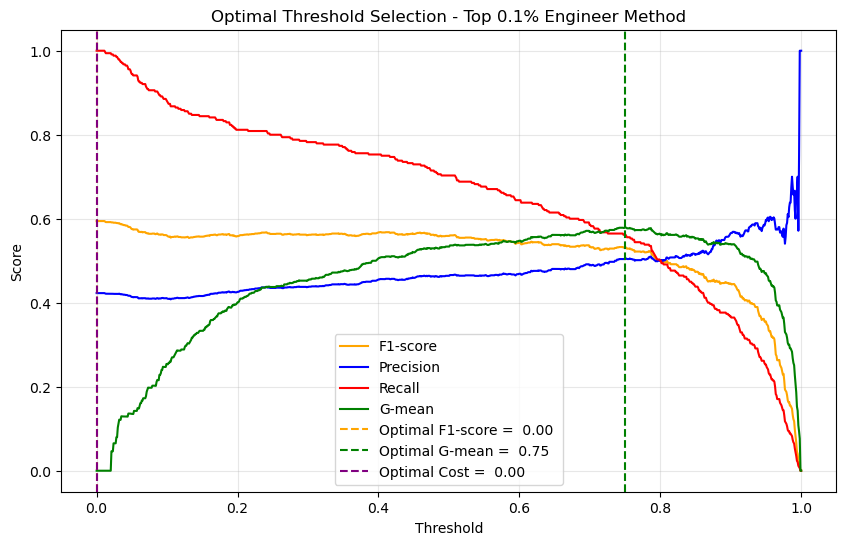

In [270]:
display_optimal_threshold(y_test, y_probs)

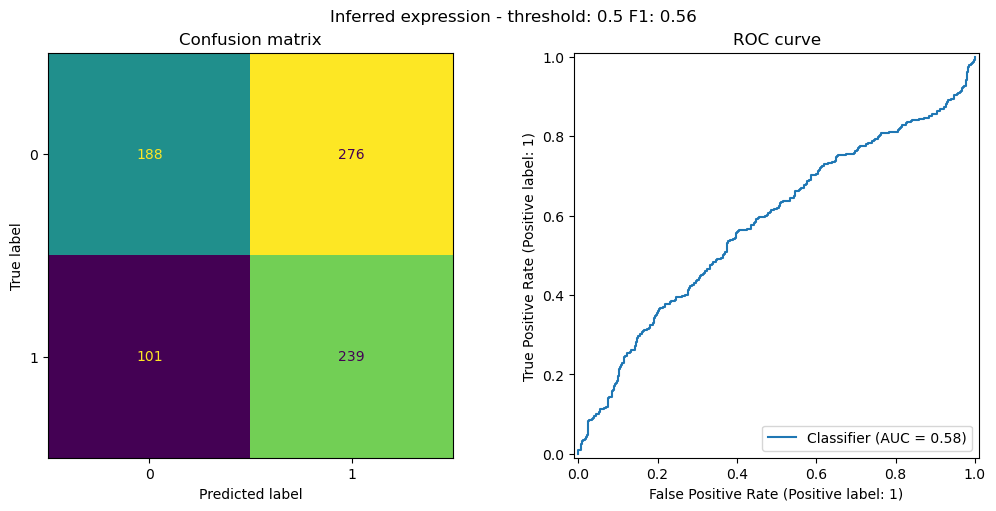

In [271]:
plot_classification_results(y_test,y_probs, threshold=thresh, vertical=False, 
                        title="Inferred expression", save_path=os.path.join(exp_path,f'confusionmatrix_A_{thresh}.png'))

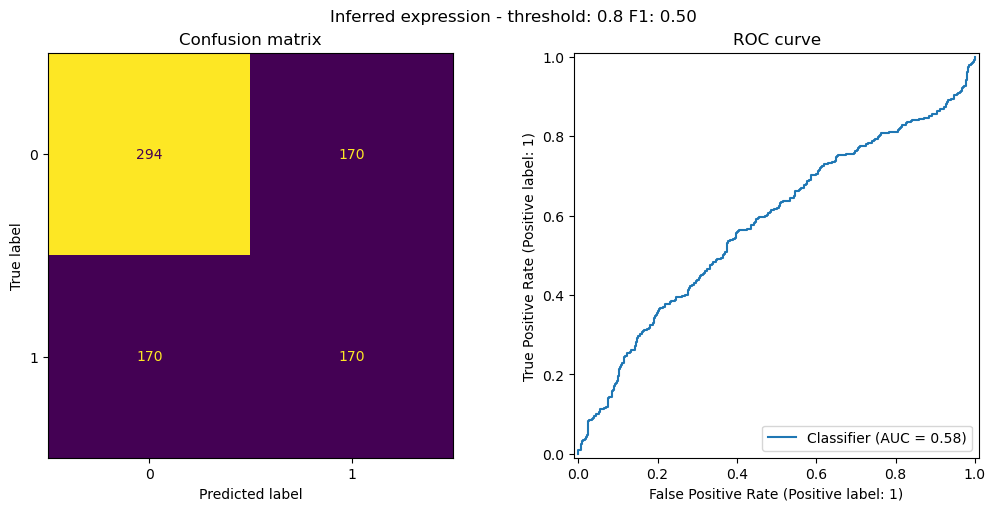

In [272]:
plot_classification_results(y_test,y_probs, threshold=0.8, vertical=False, title="Inferred expression",
                save_path=os.path.join(exp_path,'confusionmatrix_A_0.8.png'))

Check predictions

In [273]:
if USE_GSS:
    if train_idx_gss.dtype == 'int64':
        train_metadata = patch_metadata.iloc[train_idx_gss].copy()
        test_metadata = patch_metadata.iloc[test_idx_gss].copy()
    else:
        train_metadata = patch_metadata.loc[train_idx_gss].copy()
        test_metadata = patch_metadata.loc[test_idx_gss].copy()
else:
    if train_idx.dtype == 'int64':
        train_metadata = patch_metadata.iloc[train_idx].copy()
        test_metadata = patch_metadata.iloc[test_idx].copy()
    else:
        train_metadata = patch_metadata.loc[train_idx].copy()
        test_metadata = patch_metadata.loc[test_idx].copy()


In [274]:
test_metadata.shape

(804, 6)

In [275]:
test_metadata['actual'] = y_test
test_metadata['predicted'] = y_preds
test_metadata['probs'] = y_probs
test_metadata['labels'] = test_metadata.index.map(labels)
test_metadata['diff'] = test_metadata['actual'] - test_metadata['labels']
test_metadata.head()

,Slide,LEAP_ID,x,y,Response,age,actual,predicted,probs,labels,diff
SLIDE10_LEAP021_19400_43174.png,SLIDE10,LEAP021,19400,43174,Responder,47.731691,1,1,0.837127,1,0
SLIDE10_LEAP021_20296_34214.png,SLIDE10,LEAP021,20296,34214,Responder,47.731691,1,0,0.058467,1,0
SLIDE10_LEAP021_20296_35110.png,SLIDE10,LEAP021,20296,35110,Responder,47.731691,1,0,0.242574,1,0
SLIDE10_LEAP021_20296_36006.png,SLIDE10,LEAP021,20296,36006,Responder,47.731691,1,0,0.048819,1,0
SLIDE10_LEAP021_20296_36902.png,SLIDE10,LEAP021,20296,36902,Responder,47.731691,1,0,0.115649,1,0


### A4 Patient Aggregation

In [276]:
# acc = (patient["pred_pooled"] == patient["actual"]).mean()
# acc

In [277]:
df = test_metadata.sort_values('LEAP_ID')

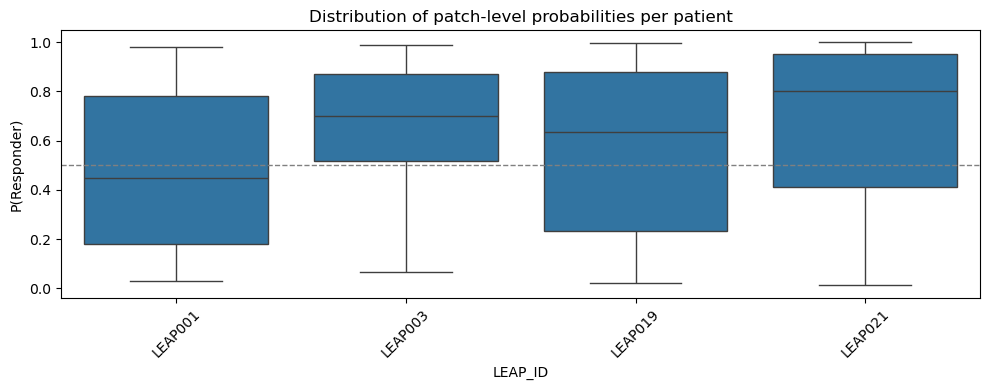

In [278]:

plt.figure(figsize=(10, 4))
sns.boxplot(data=df, x="LEAP_ID", y="probs")
plt.axhline(0.5, ls="--", c="grey", lw=1)
plt.ylabel("P(Responder)")
plt.xlabel("LEAP_ID")
plt.title("Distribution of patch-level probabilities per patient")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## B) TR Measured expression

use cores only


### B1 Data prep

In [279]:

outcome_path = os.path.join(root_path,'02-input','outcomes')

In [280]:
#actual_expr_file = 'expr_cores.csv'
actual_expr_file = 'expr_cores_nodup.csv'
expr_cores = pd.read_csv(os.path.join(tr_path,'measured',actual_expr_file), index_col=0)
expr_cores.head()

,AARD_CD45,ACTG2_CD45,ADAM15_CD45,APOC1_CD45,APOD_CD45,APOE_CD45,AREG_CD45,BCL2_CD45,BOD1L2_CD45,C1QL2_CD45,...,TAF6_PanCK,TFF3_PanCK,TMA7_PanCK,TMEM106C_PanCK,TP53_PanCK,TP63_PanCK,TPI1_PanCK,UBD_PanCK,VIM_PanCK,ZEB1_PanCK
ID,,,,,,,,,,,,,,,,,,,,,
LEAP001_12.0,2.197225,3.850148,7.309881,5.056246,3.178054,6.813445,2.484907,3.970292,2.564949,1.609438,...,5.375278,3.871201,7.673688,8.472196,6.082219,3.688879,7.109879,6.280396,8.660081,4.682131
LEAP001_2.0,1.609438,1.945910,6.204558,3.784190,2.484907,5.347108,2.079442,2.197225,1.791759,0.693147,...,3.761200,2.397895,5.683580,6.463029,3.806662,2.484907,4.919981,3.401197,6.663133,3.218876
LEAP001_4.0,1.098612,1.386294,5.768321,3.555348,1.386294,5.017280,0.693147,1.945910,1.098612,0.693147,...,5.908083,4.343805,7.985484,8.721276,6.098074,4.521789,7.478170,5.707110,8.976136,5.384495
LEAP001_6.0,1.609438,2.197225,6.129050,3.931826,1.609438,5.111988,1.945910,1.945910,1.098612,1.098612,...,5.587249,4.060443,7.723562,8.595820,6.052089,4.330733,7.305860,4.997212,8.789812,5.111988
LEAP001_7.0,1.098612,1.945910,5.564520,3.610918,1.098612,4.852030,0.693147,1.609438,1.098612,0.693147,...,5.805135,4.304065,7.973500,8.752740,6.204558,4.204693,7.465655,5.416100,8.975504,5.225747


In [281]:
if ROBUST_GENES_ONLY:
    robust_genes = joblib.load(os.path.join(root_path, '05-pathway_analysis','genes','robust_genes.joblib'))
    expr_cores = expr_cores[robust_genes]
    display(expr_cores.head())

,STRN_PanCK,CMPK1_PanCK,H1-0_PanCK,CXCL1_PanCK,ANXA8_PanCK,S100A9_PanCK,TAF6_PanCK,HSPA1B_PanCK,IGF2_PanCK,KRT17_CD45,...,USP17L3_CD45,TENT5C_CD45,CCSAP_CD45,TARP_CD45,PITX1_CD45,AREG_CD45,C7_CD45,FDCSP_CD45,PRMT8_CD45,ST6GALNAC3_CD45
ID,,,,,,,,,,,,,,,,,,,,,
LEAP001_12.0,4.762174,4.718499,5.298317,5.181784,3.988984,5.488938,5.375278,7.280697,3.367296,2.772589,...,3.401197,2.772589,3.332205,2.564949,4.060443,2.484907,3.258097,6.831954,5.572154,3.332205
LEAP001_2.0,2.995732,2.484907,3.295837,2.397895,2.564949,2.197225,3.761200,3.135494,1.609438,1.945910,...,2.484907,1.791759,2.564949,2.397895,3.178054,2.079442,1.609438,5.288267,4.043051,1.945910
LEAP001_4.0,5.170484,4.997212,5.916202,4.859812,4.510860,4.553877,5.908083,5.609472,3.526361,1.386294,...,1.791759,2.197225,1.609438,1.098612,2.833213,0.693147,2.197225,5.056246,3.583519,1.386294
LEAP001_6.0,4.912655,4.653960,5.662960,4.465908,4.465908,4.343805,5.587249,5.323010,3.401197,1.386294,...,2.197225,2.564949,2.079442,2.564949,1.945910,1.945910,1.945910,5.176150,4.204693,1.386294
LEAP001_7.0,5.111988,5.062595,5.828946,4.709530,4.574711,4.454347,5.805135,5.552960,3.401197,0.693147,...,1.791759,2.197225,2.079442,1.609438,2.944439,0.693147,1.945910,4.744932,3.713572,1.098612


In [282]:
#actual_roi_meta_file = 'roi_meta_cores.csv'
actual_roi_meta_file = 'roi_meta_cores_nodup.csv'
roi_metadata_cores = pd.read_csv(os.path.join(tr_path,'measured',actual_roi_meta_file), index_col=0)
roi_metadata_cores.head()

,LEAP_ID,Roi,ROICoordinateX,ROICoordinateY,Response,Sample_Type
ID,,,,,,
LEAP001_12.0,LEAP001,12.0,74242.78125,23623.53125,Non-Responder,DIAGNOSTIC
LEAP001_2.0,LEAP001,2.0,72508.83594,18678.61328,Non-Responder,DIAGNOSTIC
LEAP001_4.0,LEAP001,4.0,73699.89844,18678.61328,Non-Responder,DIAGNOSTIC
LEAP001_6.0,LEAP001,6.0,72506.23438,21182.68359,Non-Responder,DIAGNOSTIC
LEAP001_7.0,LEAP001,7.0,73697.29688,19989.05664,Non-Responder,DIAGNOSTIC


In [283]:
roi_metadata_cores['Response'].value_counts()

Response
Responder        1020
Non-Responder     570
Name: count, dtype: int64

In [284]:
print(f"{1020/(1020+570)*100:.2f}% - total {(1020+570)}")

64.15% - total 1590


In [285]:
patch_metadata['Response'].value_counts()

Response
Non-Responder    2474
Responder        2024
Name: count, dtype: int64

In [286]:
print(f"{2024/(2633+2024)*100:.2f}% - total {(2633+2024)}")

43.46% - total 4657


In [287]:
expr_cores.shape

(1590, 147)

In [288]:
expr_idx = expr_cores.drop_duplicates(keep='first').index

In [289]:
meta_idx = roi_metadata_cores.drop_duplicates(keep='first').index

In [290]:
roi_metadata_cores.loc[:, 'ROICoordinateX_downsampled'] =  (roi_metadata_cores["ROICoordinateX"] / DOWNSAMPLE).astype(int) #+22
roi_metadata_cores.loc[:, 'ROICoordinateY_downsampled'] =  (roi_metadata_cores["ROICoordinateY"] / DOWNSAMPLE).astype(int) #+22

In [291]:
roi_metadata_cores = roi_metadata_cores.sort_index()
expr_cores = expr_cores.sort_index()


In [292]:
assert(expr_cores.shape[0]==roi_metadata_cores.shape[0])
print(f"{roi_metadata_cores.shape[0]} rows")

1590 rows


In [293]:
roi_metadata_cores['Response'].value_counts()

Response
Responder        1020
Non-Responder     570
Name: count, dtype: int64

In [294]:
roi_metadata_cores[roi_metadata_cores['Response'].isin(['Responder','Non-Responder'])].shape

(1590, 8)

In [295]:
roi_metadata_cores.shape

(1590, 8)

In [296]:
labels_cores = (roi_metadata_cores['Response'] == 'Responder').astype(int)
y_cores = labels_cores.to_numpy()
X_cores = expr_cores.to_numpy()

In [297]:
labels_cores.shape

(1590,)

In [298]:
set_seed(77)
gss = GroupShuffleSplit(
    n_splits=1,          # just one train/test split
    test_size=0.2,       # 20 % of the groups → test set
    random_state=1  )   # reproducible


train_idx_cores, test_idx_cores = next( gss.split(X_cores,              # X
                y=y_cores,                 # y (optional)
                groups=roi_metadata_cores['LEAP_ID']))  # the grouping key

In [299]:
"""Check LEAP_IDs are only in either train or test - should pass the assertion with no output"""
train_LEAPIDs_cores = set(roi_metadata_cores['LEAP_ID'].iloc[train_idx_cores].unique())
test_LEAPIDs_cores = set(roi_metadata_cores['LEAP_ID'].iloc[test_idx_cores].unique())
assert train_LEAPIDs_cores.isdisjoint(test_LEAPIDs_cores), (
    f"Data-leakage: these LEAP_IDs are in both splits → "
    f"{train_LEAPIDs_cores & test_LEAPIDs_cores}"

)

In [300]:
X_train_cores = X_cores[train_idx_cores]
y_train_cores = y_cores[train_idx_cores]

X_test_cores  = X_cores[test_idx_cores]
y_test_cores = y_cores[test_idx_cores]

In [301]:
# groups aligned to X_train rows
if train_idx_cores.dtype == 'int64':
    groups_train_cores = roi_metadata_cores['LEAP_ID'].iloc[train_idx_cores].to_numpy()
else:
    groups_train_cores = roi_metadata_cores['LEAP_ID'].loc[train_idx_cores].to_numpy()
assert(X_train_cores.shape[0] == len(groups_train_cores))

In [302]:
roi_metadata_cores.iloc[train_idx_cores]['Response'].value_counts()

Response
Responder        818
Non-Responder    439
Name: count, dtype: int64

In [303]:
roi_metadata_cores.iloc[test_idx_cores]['Response'].value_counts()

Response
Responder        202
Non-Responder    131
Name: count, dtype: int64

In [304]:
cores_test_meta = roi_metadata_cores.iloc[test_idx_cores]
cores_test_meta['Response'].value_counts()

Response
Responder        202
Non-Responder    131
Name: count, dtype: int64

In [305]:
cores_test_meta[cores_test_meta['Response']=='Responder'].shape[0]
cores_test_meta.shape[0]

333

### B2 Train

In [306]:
# # --- model: L1 logistic with CV ---
# pipe_cores = Pipeline([
#     ("scaler", StandardScaler()),
#     ("clf", LogisticRegression(penalty="l1", solver="saga",
#                                class_weight="balanced", max_iter=5000))
# ])

# set_seed(77)
# #pipe_cores.fit(X_train_cores, y_train_cores)

use the same pipe and cv

In [307]:
#might need to define a new cv

gs_cores = GridSearchCV(
    pipe,
    param_grid=param_grid,
    scoring="roc_auc",
    cv=cv,
    n_jobs=-1,
    refit=True
)
set_seed(77) 
gs_cores.fit(X_train_cores, y_train_cores, groups=groups_train_cores)

print("Best params:", gs_cores.best_params_)
print("Best CV AUC:", gs_cores.best_score_)

best_model_cores = gs_cores.best_estimator_

Best params: {'clf__C': 100}
Best CV AUC: 0.4821509663365968


In [308]:
gs_cores.cv_results_

{'mean_fit_time': array([ 6.2996281 ,  6.3065745 ,  9.75233062, 10.61157576, 10.56176647,
         9.50846847]),
 'std_fit_time': array([1.42896071, 0.44556366, 0.55550345, 1.42656383, 0.58102445,
        1.07490741]),
 'mean_score_time': array([0.0040764 , 0.00288288, 0.00226545, 0.00385801, 0.00320419,
        0.00521413]),
 'std_score_time': array([0.00020138, 0.00063807, 0.00160547, 0.00125595, 0.0004421 ,
        0.00381396]),
 'param_clf__C': masked_array(data=[0.1, 1.0, 5.0, 10.0, 20.0, 100.0],
              mask=[False, False, False, False, False, False],
        fill_value=1e+20),
 'params': [{'clf__C': 0.1},
  {'clf__C': 1},
  {'clf__C': 5},
  {'clf__C': 10},
  {'clf__C': 20},
  {'clf__C': 100}],
 'split0_test_score': array([0.44673137, 0.39320244, 0.41465863, 0.42313699, 0.42791537,
        0.43115053]),
 'split1_test_score': array([0.42735317, 0.44612146, 0.45397131, 0.45621923, 0.45786056,
        0.45903804]),
 'split2_test_score': array([0.56787557, 0.54798595, 0.5497061

In [309]:
#y_probs_cores = pipe_cores.predict_proba(X_test_cores)[:,1]
y_probs_cores = best_model_cores.predict_proba(X_test_cores)[:,1]

In [310]:
y_preds_cores = y_probs_cores>thresh
y_preds_cores = y_preds_cores.astype(int)


In [311]:
probs_dict['modelB_test'] = y_test_cores
probs_dict['modelB_probs'] = y_probs_cores

### B3 Metrics

In [312]:
mets = display_metrics(y_test_cores, y_probs_cores, model_name='B', description='Measured cores')
metrics.append(mets)
mets

,Model,Description,Threshold,AUC,F1,Recall,Precision,Accuracy
0,B,Measured cores,0.5,0.733316,0.751174,0.792079,0.714286,0.681682


In [313]:
mets = display_metrics(y_test_cores, y_probs_cores, thresh=0.8, model_name='B', description='Measured cores')
metrics.append(mets)
mets

,Model,Description,Threshold,AUC,F1,Recall,Precision,Accuracy
0,B,Measured cores,0.8,0.733316,0.707692,0.683168,0.734043,0.657658


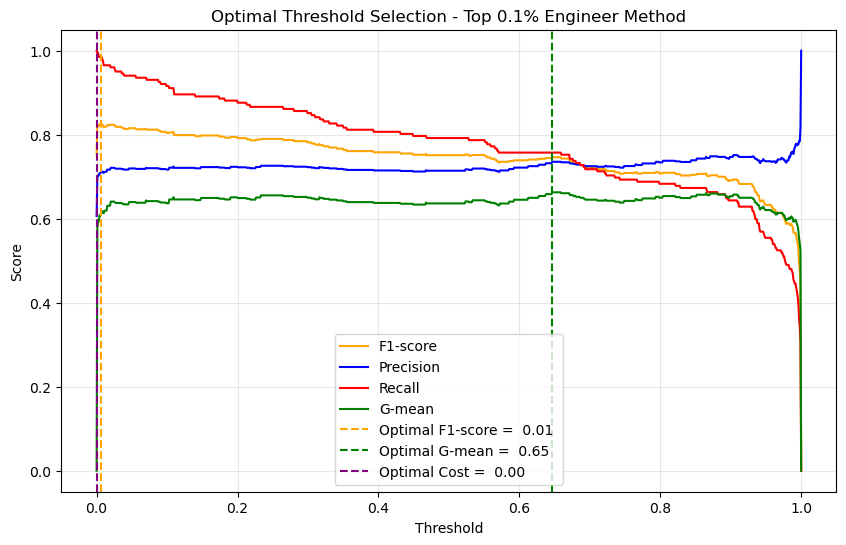

In [314]:
display_optimal_threshold(y_test_cores, y_probs_cores)

In [315]:
display_metrics(y_test_cores, y_probs_cores, thresh=0.1, model_name='B', description='Measured cores')

,Model,Description,Threshold,AUC,F1,Recall,Precision,Accuracy
0,B,Measured cores,0.1,0.733316,0.804348,0.915842,0.717054,0.72973


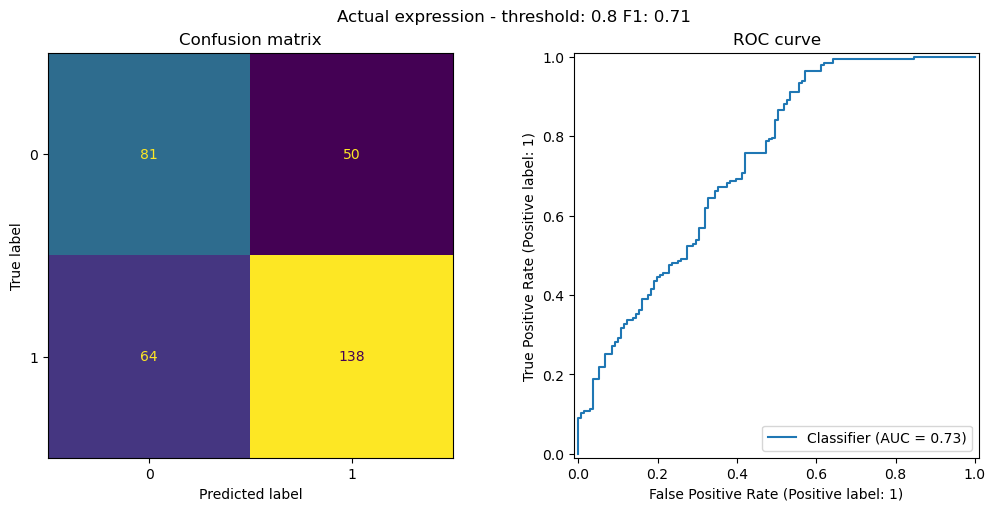

In [316]:
plot_classification_results(y_test_cores,y_probs_cores, threshold=0.8, vertical=False, title="Actual expression",
                save_path=os.path.join(exp_path,'confusionmatrix_B_0.8.png'))


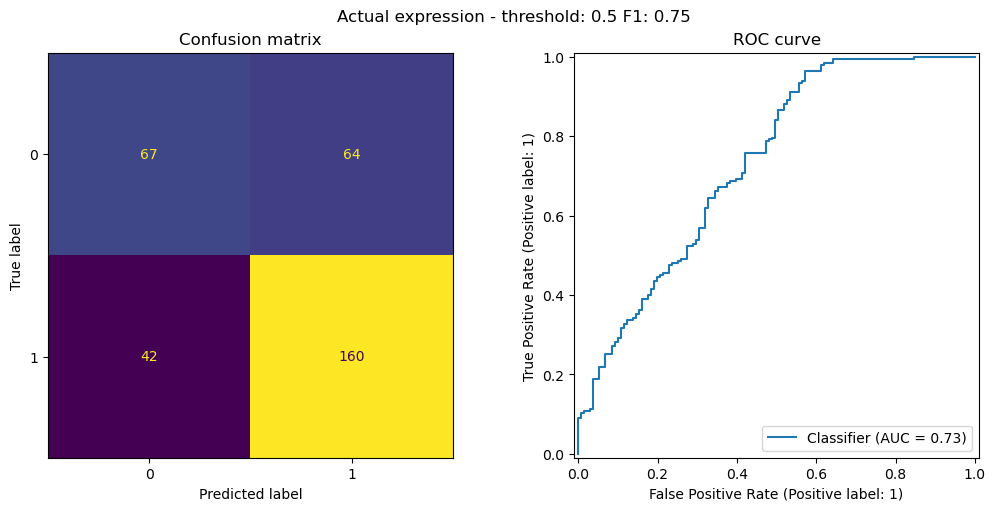

In [317]:
plot_classification_results(y_test_cores,y_probs_cores, threshold=thresh, vertical=False, title="Actual expression", 
                save_path=os.path.join(exp_path,f'confusionmatrix_B_{thresh}.png'))


In [318]:
print("INFERRED expression dataset:")
print(f"{patch_metadata.shape[0]} ROIs with both CD45 and PanCK expression across {len(patch_metadata.LEAP_ID.unique())} cores")
infer_counts = patch_metadata.groupby('LEAP_ID')['Slide'].count()
print(f"cores have between {infer_counts.min()} and {infer_counts.max()} ROIs with an average of {infer_counts.mean():.2f}")

INFERRED expression dataset:
4498 ROIs with both CD45 and PanCK expression across 14 cores
cores have between 43 and 1113 ROIs with an average of 321.29


In [319]:
print("MEASURED expression dataset:")
print(f"{roi_metadata_cores.shape[0]} ROIs with both CD45 and PanCK expression across {len(roi_metadata_cores.LEAP_ID.unique())} cores")
#Cores have between 3 and 159 ROIs with an average of 23
measured_counts = roi_metadata_cores.groupby('LEAP_ID')['Roi'].count()
print(f"cores have between {measured_counts.min()} and {measured_counts.max()} ROIs with an average of {measured_counts.mean():.2f}")

MEASURED expression dataset:
1590 ROIs with both CD45 and PanCK expression across 75 cores
cores have between 3 and 82 ROIs with an average of 21.20


## C) TR Inferred restricted to Measured stats
select same num patches from inferred as experimental data

### C.1 Data Prep

some of the cores I am using do not have GeoMx expression

In [320]:
cores_LEAPIDs = set(roi_metadata_cores.LEAP_ID.unique())

In [321]:
print("CANNOT train with:",train_leaps.difference(cores_LEAPIDs))

CANNOT train with: {'LEAP140', 'LEAP152', 'LEAP044'}


In [322]:
print("CANNOT test with:",test_leaps.difference(cores_LEAPIDs))

CANNOT test with: {'LEAP019'}


#### Try using same number of ROIs overall - 1844
make it 1500


In [323]:
print("MEASURED expression dataset:")
print(f"{roi_metadata_cores.shape[0]} ROIs with both CD45 and PanCK expression across {len(roi_metadata_cores.LEAP_ID.unique())} cores")
#Cores have between 3 and 159 ROIs with an average of 23
measured_counts = roi_metadata_cores.groupby('LEAP_ID')['Roi'].count()
print(f"cores have between {measured_counts.min()} and {measured_counts.max()} ROIs with an average of {measured_counts.mean():.0f}")
print(f"train: {len(train_idx_cores)} | test: {len(test_idx_cores)}")

MEASURED expression dataset:
1590 ROIs with both CD45 and PanCK expression across 75 cores
cores have between 3 and 82 ROIs with an average of 21
train: 1257 | test: 333


use 1590 ROIs total - 1257 train, 333 test

In [324]:
print(1257 /len(train_metadata['LEAP_ID'].unique()))
print(333/len(test_metadata['LEAP_ID'].unique()))


125.7
83.25


have to select approx 130 tiles per core to get to the same overall number

In [325]:
num_patches_to_sample = 125

In [326]:

sampled_train_metadata = train_metadata \
.groupby('LEAP_ID', group_keys=False) \
.apply(
        lambda g: g.sample(
            n=min(len(g),num_patches_to_sample),
            random_state=77
        )
    )

sampled_test_metadata = test_metadata \
.groupby('LEAP_ID', group_keys=False) \
.apply(
        lambda g: g.sample(
            n=min(len(g),num_patches_to_sample),
            random_state=77
        )
    )
print(f"using {num_patches_to_sample} patches per core gives:\n \
    train: {sampled_train_metadata.shape[0]} \
    test: {sampled_test_metadata.shape[0]} \
    total: {sampled_train_metadata.shape[0]+sampled_test_metadata.shape[0]} ")
print("aiming for\n \
    train: 1257 \
    test: 333 \
    total: 1509\n")

using 125 patches per core gives:
     train: 1233     test: 361     total: 1594 
aiming for
     train: 1257     test: 333     total: 1509



C:\Users\hooll\AppData\Local\Temp\ipykernel_36356\39330429.py:3: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(
C:\Users\hooll\AppData\Local\Temp\ipykernel_36356\39330429.py:12: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(


In [327]:
X_train_sampled =  expr.loc[sampled_train_metadata.index].to_numpy()
y_train_sampled =  labels.loc[sampled_train_metadata.index].to_numpy()

X_test_sampled =  expr.loc[sampled_test_metadata.index].to_numpy()
y_test_sampled =  labels.loc[sampled_test_metadata.index].to_numpy()

In [328]:
# groups aligned to X_train rows
groups_train_sampled = sampled_train_metadata['LEAP_ID'].to_numpy()
assert(X_train_sampled.shape[0] == len(groups_train_sampled))

In [329]:
sampled_train_metadata['Response'].value_counts()

Response
Responder        625
Non-Responder    608
Name: count, dtype: int64

In [330]:
print(f"{625/(625+608)*100:.2f}% - total {(625+608)}")

50.69% - total 1233


### C.2 Train

In [331]:
# # # --- model: L1 logistic with CV ---
# pipe_sampled = Pipeline([
#     ("scaler", StandardScaler()),
#     ("clf", LogisticRegression(penalty="l1", solver="saga",
#                                class_weight="balanced", max_iter=5000))
# ])
# set_seed(77)
# pipe_sampled.fit(X_train_sampled, y_train_sampled)

In [332]:
#might need to define a new cv

gs_sampled = GridSearchCV(
    pipe,
    param_grid=param_grid,
    scoring="roc_auc",
    cv=cv,
    n_jobs=-1,
    refit=True
)
set_seed(77) 
gs_sampled.fit(X_train_sampled, y_train_sampled, groups=groups_train_sampled)

print("Best params:", gs_sampled.best_params_)
print("Best CV AUC:", gs_sampled.best_score_)

best_model_sampled = gs_sampled.best_estimator_

Best params: {'clf__C': 0.1}
Best CV AUC: 0.7232251522633745


In [333]:
gs_sampled.cv_results_

{'mean_fit_time': array([ 5.05270306, 10.00074681, 11.42541409, 10.85096693, 11.50774026,
        12.09959086]),
 'std_fit_time': array([2.00573649, 1.19216484, 0.79034072, 0.33710609, 1.19814565,
        1.69702531]),
 'mean_score_time': array([0.00570695, 0.00458972, 0.00421453, 0.00418576, 0.00357095,
        0.00458399]),
 'std_score_time': array([0.00236972, 0.00106503, 0.00165271, 0.00062157, 0.00068131,
        0.00042148]),
 'param_clf__C': masked_array(data=[0.1, 1.0, 5.0, 10.0, 20.0, 100.0],
              mask=[False, False, False, False, False, False],
        fill_value=1e+20),
 'params': [{'clf__C': 0.1},
  {'clf__C': 1},
  {'clf__C': 5},
  {'clf__C': 10},
  {'clf__C': 20},
  {'clf__C': 100}],
 'split0_test_score': array([0.51012346, 0.4371358 , 0.47496296, 0.488     , 0.49358025,
        0.49804938]),
 'split1_test_score': array([0.690176, 0.611552, 0.572128, 0.54784 , 0.531968, 0.516768]),
 'split2_test_score': array([0.969376, 0.960096, 0.905472, 0.888352, 0.874976, 0.8

In [334]:
#y_probs_sampled = pipe_sampled.predict_proba(X_test_sampled)[:,1]
y_probs_sampled = best_model_sampled.predict_proba(X_test_sampled)[:,1]


In [335]:
y_preds_sampled = y_probs_sampled>thresh
y_preds_sampled = y_preds_sampled.astype(int)

In [336]:
probs_dict['modelC_test'] = y_test_sampled
probs_dict['modelC_probs'] = y_probs_sampled

### C.3 Metrics

In [337]:
mets = display_metrics(y_test_sampled, y_probs_sampled, model_name='C', description='Inferred Restricted')
metrics.append(mets)
mets

,Model,Description,Threshold,AUC,F1,Recall,Precision,Accuracy
0,C,Inferred Restricted,0.5,0.530949,0.473988,0.656,0.371041,0.495845


In [338]:
mets = display_metrics(y_test_sampled, y_probs_sampled, thresh=0.8, model_name='C', description='Inferred Restricted')
metrics.append(mets)
mets

,Model,Description,Threshold,AUC,F1,Recall,Precision,Accuracy
0,C,Inferred Restricted,0.8,0.530949,0.369748,0.352,0.389381,0.584488


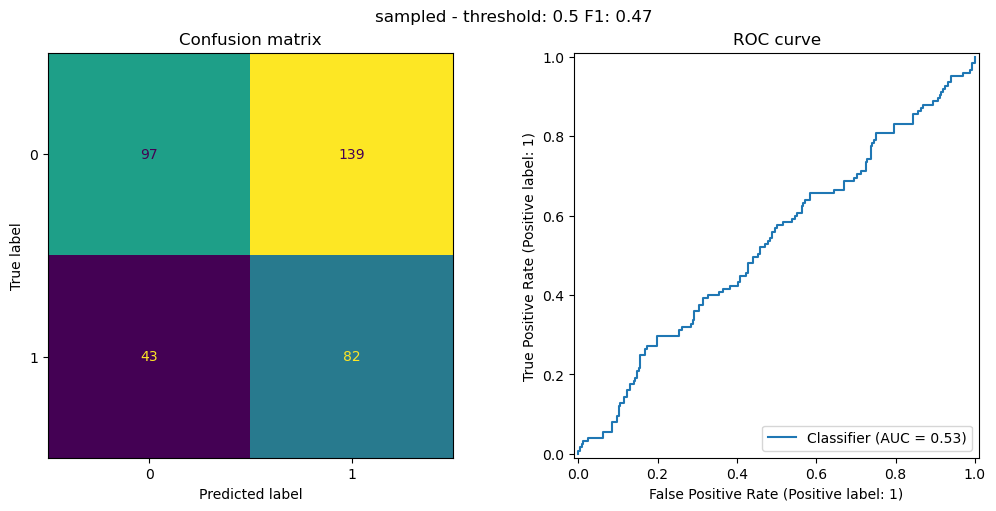

In [339]:
plot_classification_results(y_test_sampled,y_probs_sampled, threshold=thresh, vertical=False, title="sampled",
                save_path=os.path.join(exp_path,'confusionmatrix_C_0.5.png'))

for patches where the patient is NOT a responder, the model usually correctly predicts not a responder
for patches where the patient IS a responder, the model is 50% correct

lets see how that works at a patient level

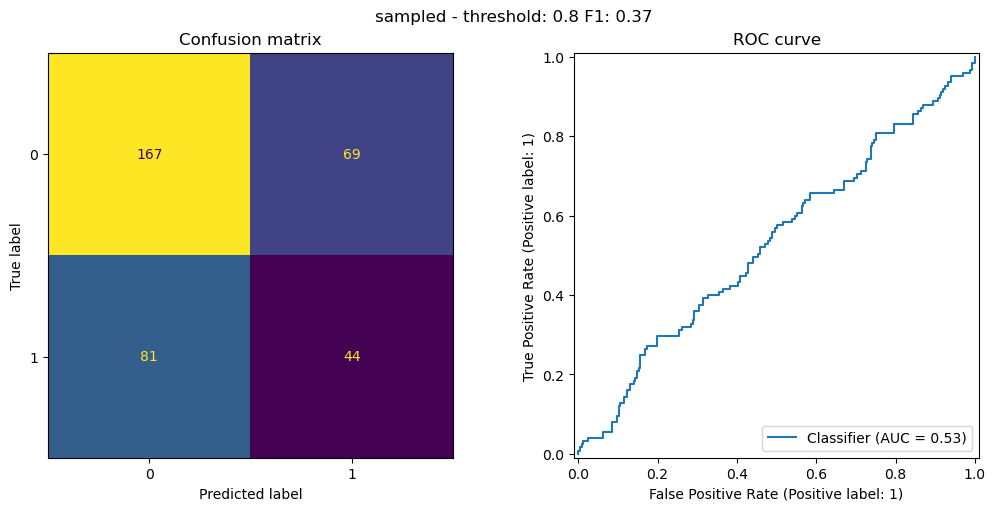

In [340]:
plot_classification_results(y_test_sampled,y_probs_sampled, threshold=0.8, vertical=False, title="sampled",
                save_path=os.path.join(exp_path,'confusionmatrix_C_0.8.png'))

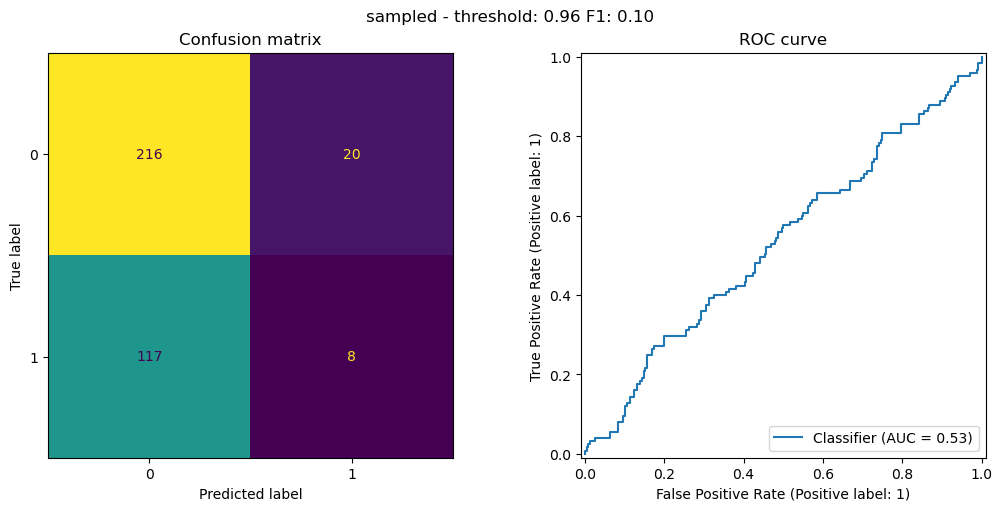

In [341]:
plot_classification_results(y_test_sampled,y_probs_sampled, threshold=0.96, vertical=False, title="sampled")

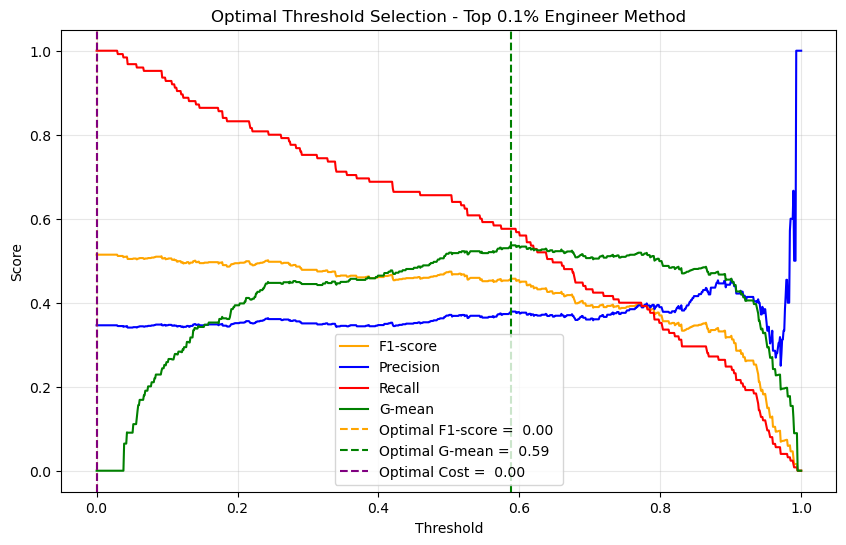

In [342]:
display_optimal_threshold(y_test_sampled, y_probs_sampled)

In [343]:
print("MEASURED expression dataset:")
print(f"{roi_metadata_cores.shape[0]} ROIs with both CD45 and PanCK expression across {len(roi_metadata_cores.LEAP_ID.unique())} cores")
#Cores have between 3 and 159 ROIs with an average of 23
measured_counts = roi_metadata_cores.groupby('LEAP_ID')['Roi'].count()
print(f"cores have between {measured_counts.min()} and {measured_counts.max()} ROIs with an average of {measured_counts.mean():.0f}")

MEASURED expression dataset:
1590 ROIs with both CD45 and PanCK expression across 75 cores
cores have between 3 and 82 ROIs with an average of 21


In [344]:
print("SAMPLED inferred expression dataset:")
print(f"{sampled_train_metadata.shape[0]+sampled_test_metadata.shape[0]} ROIs with both CD45 and PanCK expression across {len(sampled_train_metadata.LEAP_ID.unique())+len(sampled_test_metadata.LEAP_ID.unique())} cores")
#Cores have between 3 and 159 ROIs with an average of 23
sampled_counts = pd.concat([sampled_train_metadata.groupby('LEAP_ID')['Slide'].count(),sampled_test_metadata.groupby('LEAP_ID')['Slide'].count()])

print(f"cores have between {sampled_counts.min()} and {sampled_counts.max()} ROIs with an average of {sampled_counts.mean():.0f}")

SAMPLED inferred expression dataset:
1594 ROIs with both CD45 and PanCK expression across 14 cores
cores have between 43 and 125 ROIs with an average of 114


## ABC Summary

In [345]:
def report_prevalence(df_to_report, idx=None):
    if idx is None:
        df = df_to_report.copy()
    else:
        if idx.dtype == 'int64':
            df = df_to_report.iloc[idx].copy()
        else:
            df = df_to_report.loc[idx].copy()

    resp_count = df[df['Response']=='Responder'].shape[0]
    total = df.shape[0]

    print(f"{resp_count} Responders - {resp_count/total*100:.2f}% - total {total}")




In [346]:
report_prevalence(patch_metadata, train_idx.append(test_idx))
report_prevalence(patch_metadata,train_idx)
report_prevalence(patch_metadata,test_idx)

1632 Responders - 48.10% - total 3393
1292 Responders - 49.90% - total 2589
340 Responders - 42.29% - total 804


In [347]:

report_prevalence(roi_metadata_cores)
report_prevalence(roi_metadata_cores,train_idx_cores)
report_prevalence(roi_metadata_cores,test_idx_cores)

1020 Responders - 64.15% - total 1590
818 Responders - 65.08% - total 1257
202 Responders - 60.66% - total 333


In [348]:
report_prevalence(pd.concat([sampled_train_metadata,sampled_test_metadata]))
report_prevalence(sampled_train_metadata)
report_prevalence(sampled_test_metadata)

750 Responders - 47.05% - total 1594
625 Responders - 50.69% - total 1233
125 Responders - 34.63% - total 361


Model A:
Whole dataset:  1632 Responders - 48.10% - total 3393
Train:          1292 Responders - 49.90% - total 2589
Test:           340 Responders - 42.29% - total 804


Model B:
Whole dataset:  1020 Responders - 64.15% - total 1590
Train:          818 Responders - 65.08% - total 1257
Test:           202 Responders - 60.66% - total 333

Model C:
Whole dataset:  750 Responders - 47.05% - total 1594
Train:          625 Responders - 50.69% - total 1233
Test:           125 Responders - 34.63% - total 361

## D) TR with Image Embeddings only

### D.1 Data Prep

In [153]:
feature_matrix_df.shape

(4498, 5120)

In [154]:
feature_matrix_df.head()

,0,1,2,3,4,5,6,7,8,9,...,5110,5111,5112,5113,5114,5115,5116,5117,5118,5119
SLIDE10_LEAP021_19400_43174.png,0.348899,1.612066,0.063582,1.464199,0.702382,-0.569153,2.270594,-0.714870,-0.483752,-0.478086,...,0.325701,-0.491925,-0.894595,0.839113,0.068694,-0.270897,0.582426,1.546655,-1.681189,-1.328748
SLIDE10_LEAP021_20296_34214.png,-2.324131,0.781844,-0.181304,1.706208,0.843611,-0.609286,-0.108469,-0.767871,-0.324234,1.062612,...,0.143704,0.212654,0.810361,0.093385,-0.254718,1.913309,1.098460,1.087227,0.554016,-1.456098
SLIDE10_LEAP021_20296_35110.png,0.755672,1.018150,-0.551032,0.869633,-0.013513,-1.127886,-0.006792,-0.071494,-1.056290,0.139018,...,0.377277,0.450101,-0.748694,-0.879170,-0.104315,0.969053,-0.442599,0.741839,0.364377,-0.471646
SLIDE10_LEAP021_20296_36006.png,1.899637,-0.194250,-0.107565,1.564669,0.147580,0.590484,-1.426739,0.499366,-0.202283,1.142288,...,0.555943,0.088424,0.266557,0.284923,-0.345419,-0.055847,0.177777,1.181366,0.700709,-1.090053
SLIDE10_LEAP021_20296_36902.png,0.328736,-0.518203,0.788625,1.834552,0.429434,-0.161770,1.690100,0.759631,0.474539,1.218817,...,0.537134,0.074693,-0.246325,0.945683,-0.383895,-0.639774,-0.184708,1.372382,0.385180,-0.669456


In [155]:
expr.shape

(4498, 147)

In [156]:
feature_matrix_df = feature_matrix_df.loc[image_names]

In [157]:
feature_matrix_df = feature_matrix_df.sort_index()
assert (patch_metadata.index == feature_matrix_df.index).all()

In [158]:
assert (labels.index == feature_matrix_df.index).all()

In [159]:
X_imgfeat = feature_matrix_df#.to_numpy()
y_imgfeat = labels#.to_numpy() # essentially y_imgfeat=y

In [160]:
X_imgfeat.loc[train_idx]

,0,1,2,3,4,5,6,7,8,9,...,5110,5111,5112,5113,5114,5115,5116,5117,5118,5119
SLIDE33_LEAP077_54613_126529.png,0.046149,-0.684940,-2.272599,1.047520,0.440836,-0.387717,-0.836689,-1.090407,-0.137810,-0.663344,...,-0.010071,0.157978,-0.246845,0.577168,0.409461,-1.223375,0.093722,0.227520,-0.495969,-0.529392
SLIDE33_LEAP077_26837_149825.png,-2.017800,-2.262191,-1.450342,1.738805,-0.657044,0.065869,0.475553,1.440265,-0.193789,0.559719,...,0.270424,0.534289,0.627078,-0.793681,0.232606,0.514295,-0.015725,0.008354,0.010139,-0.631924
SLIDE33_LEAP077_41173_134593.png,0.145644,0.003070,-0.519990,1.242527,1.140021,0.797688,1.359585,0.647363,-0.464543,-0.444347,...,0.459749,-0.983464,0.392093,0.449635,0.163679,-1.157113,-0.564744,-0.904973,-0.298736,-0.739311
SLIDE33_LEAP077_44757_133697.png,1.920576,1.181031,-0.711115,1.592609,0.453249,-0.290103,-1.260727,1.504350,-0.217525,1.413899,...,0.685245,-0.014778,0.468934,0.166710,0.232840,-0.695436,-0.227900,-0.945332,0.128706,-0.053838
SLIDE33_LEAP077_43861_149825.png,-1.153868,-0.682385,-1.341268,1.234985,-0.568264,0.818105,0.302098,0.605633,-0.545189,1.310223,...,0.140966,-0.545605,0.767219,-0.478255,0.021413,0.334349,0.393581,0.070432,0.933618,-0.601363
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
SLIDE55_LEAP140_15580_25781.png,-1.078776,-0.204426,-0.681159,1.130704,0.605293,-0.217430,-0.864428,-0.254280,-1.678934,-0.410545,...,0.229655,0.240375,0.705956,-0.599937,0.065435,1.200624,-0.008702,0.885791,-1.251411,-0.416378
SLIDE55_LEAP140_19164_26677.png,-0.284675,1.309076,0.566265,0.170842,-0.846630,-0.797835,0.245147,-0.736247,-2.457541,1.179923,...,0.484364,0.127596,-1.785441,-0.369699,0.565751,-0.127150,-0.410493,-0.104157,-0.354836,-1.165819
SLIDE55_LEAP140_17372_15925.png,0.660946,1.409087,-0.542463,0.994623,-0.444913,0.555688,0.823396,0.268502,-0.795001,-0.420355,...,0.426999,0.418793,-0.784552,-0.388405,0.277132,0.052303,-0.790526,0.582250,-0.017804,-0.594799
SLIDE55_LEAP140_10204_25781.png,-1.049326,-0.890875,-1.057673,0.928337,1.017649,-0.619502,-0.458935,-1.714709,-0.657407,-0.027460,...,0.623308,-0.088168,-0.805041,-0.454363,0.167925,0.709338,-0.125029,0.680936,-2.034583,-0.816805


In [161]:
if USE_GSS:

    X_train_imgfeat = X_imgfeat.iloc[train_idx_gss].to_numpy()
    y_train_imgfeat = y_imgfeat.iloc[train_idx_gss].to_numpy()

    X_test_imgfeat  = X_imgfeat.iloc[test_idx_gss].to_numpy()
    y_test_imgfeat = y_imgfeat.iloc[test_idx_gss].to_numpy()

else:
    if train_idx.dtype == 'int64':
        X_train_imgfeat = X_imgfeat.iloc[train_idx].to_numpy()
        y_train_imgfeat = y_imgfeat.iloc[train_idx].to_numpy()

        X_test_imgfeat  = X_imgfeat.iloc[test_idx].to_numpy()
        y_test_imgfeat = y_imgfeat.iloc[test_idx].to_numpy()
    else:
        X_train_imgfeat = X_imgfeat.loc[train_idx].to_numpy()
        y_train_imgfeat = y_imgfeat.loc[train_idx].to_numpy()

        X_test_imgfeat  = X_imgfeat.loc[test_idx].to_numpy()
        y_test_imgfeat = y_imgfeat.loc[test_idx].to_numpy()

### D.2 Train

the pipeline alone takes 10m to fit

In [162]:

# pipe_imgfeat = Pipeline([
#     ("scaler", StandardScaler()), ## added 02/02/26
#     ("clf", LogisticRegression(
#         penalty="l1",
#         solver="saga",
#         class_weight="balanced",
#         max_iter=5000,
#         random_state=77
#     ))
# ])

# set_seed(77)
# #pipe_imgfeat.fit(X_train_imgfeat, y_train_imgfeat)
# param_grid = {"clf__C": [1]} #np.logspace(-3, 2, 10)}

# cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=77)



In [ ]:
patient.groupby(['actual','pred_pooled']).agg(
    Total_Patches=("n_patches", "sum"),
    Total_Patients=("n_patches", "count"),       
    p_mean=("p_mean", "mean"),               
    conf_mean=("confidence", "mean"),        
)

WARNING gs_imgfeat takes over an hour to fit

In [ ]:
patch_metadata['Response'].value_counts()

In [ ]:
#32 mins
gs_imgfeat = GridSearchCV(
    pipe,
    param_grid=param_grid,
    scoring="roc_auc",
    cv=cv,
    n_jobs=-1,
    refit=True
)
set_seed(77)
gs_imgfeat.fit(X_train_imgfeat, y_train_imgfeat, groups=groups_train)


In [ ]:
###### TEMP EXP1-run_2026-02-14_droptissue_tunec
#gs_imgfeat = joblib.load(os.path.join(tr_path, 'metrics','EXP1-run_2026-02-14_droptissue_tunec','gs_imgfeat_2026-02-14.joblib'))

In [ ]:
gs_imgfeat.cv_results_

In [ ]:
print(gs_imgfeat.best_params_)
print(gs_imgfeat.best_score_)

In [ ]:
best_model_imgfeat = gs_imgfeat.best_estimator_

In [ ]:
thresh = 0.5
y_probs_imgfeat = best_model_imgfeat.predict_proba(X_test_imgfeat)[:,1]
#y_probs_imgfeat = pipe_imgfeat.predict_proba(X_test_imgfeat)[:,1]

y_preds_imgfeat = (y_probs_imgfeat>thresh).astype(int)

In [ ]:

test_metadata['predicted_imgfeat'] = y_preds_imgfeat
test_metadata['probs_imgfeat'] = y_probs_imgfeat

In [ ]:
probs_dict['modelD_test'] = y_test
probs_dict['modelD_probs'] = y_probs_imgfeat

### D.3 Metrics

In [ ]:
assert(y_test==y_test_imgfeat).all()

In [ ]:
mets = display_metrics(y_test, y_probs_imgfeat, model_name='D', description='Img Embeddings only')
metrics.append(mets)
mets

In [ ]:
mets = display_metrics(y_test, y_probs_imgfeat, thresh=0.8, model_name='D', description='Img Embeddings only')
metrics.append(mets)
mets

In [ ]:

y_preds_imgfeat_08 = (y_probs_imgfeat> 0.8).astype(int)

plot_classification_results(y_test,y_probs_imgfeat, threshold=0.8, vertical=False, title="Image features only",
                save_path=os.path.join(exp_path,'confusionmatrix_D_0.8.png'))

In [ ]:

plot_classification_results(y_test,y_probs_imgfeat, threshold=thresh, vertical=False, title="Image features only",
                save_path=os.path.join(exp_path,'confusionmatrix_D_0.5.png'))

In [ ]:
plot_classification_results(y_test,y_probs_imgfeat, threshold=0.95, vertical=False, title="Image features only")

In [ ]:
display_optimal_threshold(y_test, y_probs_imgfeat)

In [ ]:
# df = test_metadata.sort_values('LEAP_ID') #[test_metadata['LEAP_ID']!='LEAP057']
# g = sns.FacetGrid(
#     df,
#     col="LEAP_ID",
#     col_wrap=2,
#     height=2.5,
#     sharex=True,
#     sharey=True
# )

# g.map_dataframe(sns.histplot, x="probs_imgfeat", bins=15)
# g.map(plt.axvline, x=0.5, ls="--", color="black", lw=1)

# g.set_axis_labels("P(Responder)", "Count")
# plt.suptitle("Patch-level probability distributions")
# plt.tight_layout()
# plt.show()


In [ ]:


# df = test_metadata.sort_values('LEAP_ID') 
# fig, ax = plt.subplots(figsize=(7, 4))

# # Distribution (violin)
# sns.violinplot(
#     data=df, x="LEAP_ID", y="probs_imgfeat",
#     inner=None, cut=0, linewidth=1, ax=ax,
#     bw_adjust=0.7  # tweak 0.5–1.5 if needed
# )

# # Show the actual patch probs (this usually explains the “spikes”)
# sns.stripplot(
#     data=df, x="LEAP_ID", y="probs_imgfeat",
#     jitter=0.18, size=3, alpha=0.5, color="black", ax=ax
# )


# ax.axhline(0.5, ls="--", color="black", lw=1)
# ax.set_ylim(-0.02, 1.02)
# ax.set_ylabel("P(Responder)")
# ax.set_xlabel("LEAP_ID")
# ax.set_title("WSI only - Patch-level probability distributions")
# plt.tight_layout()
# plt.show()


## E) TR Combine Inferred + Img Embeddings

### E.1 Data Prep

NEED TO SCALE THE FEATURES and use the same pipeline for both img feat only img+SGE

combine expr with feature_matrix_df

In [ ]:
assert (feature_matrix_df.index == expr.index).all()

In [ ]:
all_features_df = pd.concat(
    [feature_matrix_df, expr],
    axis=1
)

In [ ]:
all_features_df.isna().any().any()

In [ ]:
assert all_features_df.isna().sum().sum() == 0
assert all_features_df.shape[0] == feature_matrix_df.shape[0]
assert (labels.index == all_features_df.index).all()

In [ ]:
X_allfeat = all_features_df#.to_numpy()
y_allfeat = labels#.to_numpy()

In [ ]:
X_allfeat.columns = X_allfeat.columns.astype(str)

In [ ]:
X_train_allfeat = X_allfeat.loc[train_idx]
y_train_allfeat = y_allfeat.loc[train_idx]

X_test_allfeat  = X_allfeat.loc[test_idx]
y_test_allfeat = y_allfeat.loc[test_idx]

### E.2 Train

takes 28 mins to train

don't need to redefine the pipeline and cv - use the same as for img only

In [ ]:
#### use pipe_imgfeat
# pipe_allfeat = Pipeline([
#     ("scaler", StandardScaler()), 
#     ("clf", LogisticRegression(
#         penalty="l1",
#         solver="saga",
#         class_weight="balanced",
#         max_iter=5000,
#         random_state=77
#     ))
# ])

# set_seed(77)
#param_grid = {"clf__C": [1]} #np.logspace(-3, 2, 10)}

#cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=77)

#pipe_allfeat.fit(X_train_allfeat, y_train_allfeat)

In [ ]:
img_cols  = feature_matrix_df.columns.astype(str)
expr_cols = expr.columns.astype(str)

In [ ]:
len(expr_cols)

In [ ]:
feature_matrix_df.head()

In [ ]:
assert set(img_cols).isdisjoint(expr_cols)
assert list(X_allfeat.columns) == list(img_cols) + list(expr_cols)


In [ ]:
from sklearn.compose import ColumnTransformer

preprocess = ColumnTransformer(
    transformers=[
        ("img", StandardScaler(), img_cols),
        ("expr", StandardScaler(), expr_cols),
    ]
)

pipe_allfeat = Pipeline([
    ("prep", preprocess),
    ("clf", LogisticRegression(
        penalty="l1",
        solver="saga",
        class_weight="balanced",
        max_iter=5000,
        random_state=77
    ))
])


In [ ]:

gs_allfeat = GridSearchCV(
    pipe_allfeat,#pipe,
    param_grid=param_grid,
    scoring="roc_auc",
    cv=cv,
    n_jobs=-1,
    refit=True
)
set_seed(77)
#gs_allfeat.fit(X_train_allfeat, y_train_allfeat, groups=groups_train)


<div class="alert alert-block alert-warning">
TEMPORARY HACK to avoid training on all features while it is the same as image features 
</div>

In [ ]:
gs_allfeat = gs_imgfeat

In [ ]:
print(gs_allfeat.best_params_)
print(gs_allfeat.best_score_)

In [ ]:
joblib.dump(gs_allfeat, os.path.join(root_path,'06-treatment_response',f"gs_allfeat_new_{today}_nocalib.joblib"))


In [ ]:
best_model_allfeat = gs_allfeat.best_estimator_

In [ ]:
thresh = 0.5
# y_probs_allfeat = best_model_allfeat.predict_proba(X_test_allfeat)[:,1]
# #y_probs_allfeat = pipe_allfeat.predict_proba(X_test_allfeat)[:,1]
y_probs_allfeat = y_probs_imgfeat


y_preds_allfeat = (y_probs_allfeat>thresh).astype(int)

In [ ]:

test_metadata['predicted_allfeat'] = y_preds_allfeat
test_metadata['probs_allfeat'] = y_probs_allfeat

In [ ]:
probs_dict['modelE_test'] = y_test
probs_dict['modelE_probs'] = y_probs_allfeat

### E.3 Metrics

In [ ]:
assert(y_test==y_test_allfeat).all()

In [ ]:
mets = display_metrics(y_test, y_probs_imgfeat, model_name='E', description='Inferred + Img Embeddings')
metrics.append(mets)
mets

In [ ]:
mets = display_metrics(y_test, y_probs_imgfeat, thresh=0.8, model_name='E', description='Inferred + Img Embeddings')
metrics.append(mets)
mets

In [ ]:

plot_classification_results(y_test,y_probs_imgfeat, threshold=0.8, vertical=False, title="WSI+inferred expr",
                save_path=os.path.join(exp_path,'confusionmatrix_E_0.8.png'))

In [ ]:
plot_classification_results(y_test,y_probs_allfeat, threshold=thresh, vertical=False, title="WSI+inferred expr",
                save_path=os.path.join(exp_path,'confusionmatrix_E_0.5.png'))

In [ ]:
display_optimal_threshold(y_test, y_probs_allfeat)

In [ ]:

plot_classification_results(y_test,y_probs_imgfeat, threshold=0.95, vertical=False, title="WSI+inferred expr")

In [ ]:
joblib.dump(gs, os.path.join(exp_path,f"gs_{today}.joblib"))
joblib.dump(gs_imgfeat, os.path.join(exp_path,f"gs_imgfeat_{today}.joblib"))
joblib.dump(gs_allfeat, os.path.join(exp_path,f"gs_allfeat_new_{today}.joblib"))
joblib.dump(gs_cores, os.path.join(exp_path,f"gs_cores_{today}.joblib"))
joblib.dump(gs_sampled, os.path.join(exp_path,f"gs_sampled_{today}.joblib"))
#joblib.dump(pipe_cores, os.path.join(exp_path,f"pipe_cores_{today}.joblib"))
#joblib.dump(pipe_imgfeat, os.path.join(exp_path,f"pipe_imgfeat_{today}.joblib"))
#joblib.dump(pipe_allfeat, os.path.join(exp_path,f"pipe_allfeat_{today}.joblib"))


In [ ]:
#metrics.append(stats_df))

metrics_df = pd.concat(metrics, axis=0).reset_index(drop=True)
metrics_df

In [ ]:
metrics_df.to_csv(os.path.join(exp_path, 'metrics.csv'))

In [ ]:
exp_path

# Save Probs

In [ ]:
tr_path

In [ ]:
suffix = ''
if APPLY_CALIB:
    suffix = '_cal'
print(f"suffix is:  *{suffix}*")

In [ ]:
cores_df = pd.DataFrame({
        'ytrue': probs_dict['modelB_test'] ,
        'yprobs': probs_dict['modelB_probs'] 
    }    )
cores_df.to_csv(os.path.join(tr_path,'probs',f'cores_df{suffix}.csv'))

In [ ]:
sampled_df = pd.DataFrame({
        'ytrue': probs_dict['modelC_test'] ,
        'yprobs': probs_dict['modelC_probs'] 
    }    )
sampled_df.to_csv(os.path.join(tr_path,'probs',f'sampled_df{suffix}.csv'))

In [ ]:


probs_df = pd.DataFrame({
        'ytrue': probs_dict['modelA_test'] ,
        'yprobs_A': probs_dict['modelA_probs'] ,
        #'yprobs_D': probs_dict['modelD_probs'] ,
        #'yprobs_E': probs_dict['modelE_probs'] ,
    }    )
probs_df.to_csv(os.path.join(tr_path,'probs',f'probs{suffix}.csv'))

In [ ]:
test_metadata[test_metadata['LEAP_ID'].isin(['LEAP019','LEAP021'])].to_csv(os.path.join(tr_path,'probs','testmeta_LEAP019_LEAP021.csv'))

# Figure 4
 

In [ ]:
fig_path = '../paper/figures'


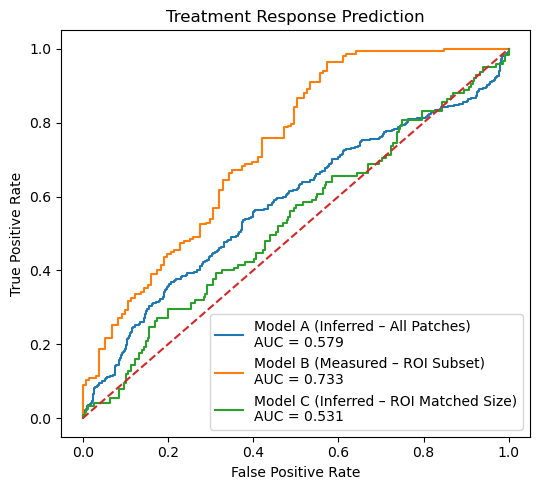

In [351]:

from sklearn.metrics import roc_curve, roc_auc_score

"""
Single-panel ROC comparison: Model A vs B vs C
"""



# --- Compute ROC + AUC ---
fpr_A, tpr_A, _ = roc_curve(y_test, y_probs)
auc_A = roc_auc_score(y_test, y_probs)

fpr_B, tpr_B, _ = roc_curve(y_test_cores, y_probs_cores)
auc_B = roc_auc_score(y_test_cores, y_probs_cores)

fpr_C, tpr_C, _ = roc_curve(y_test_sampled, y_probs_sampled)
auc_C = roc_auc_score(y_test_sampled, y_probs_sampled)

# --- Plot ---
plt.figure(figsize=(5.5, 5.0))

plt.plot(fpr_A, tpr_A, label=f"Model A (Inferred – All Patches)\nAUC = {auc_A:.3f}")
plt.plot(fpr_B, tpr_B, label=f"Model B (Measured – ROI Subset)\nAUC = {auc_B:.3f}")
plt.plot(fpr_C, tpr_C, label=f"Model C (Inferred – ROI Matched Size)\nAUC = {auc_C:.3f}")

# Diagonal reference
plt.plot([0, 1], [0, 1], linestyle="--")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Treatment Response Prediction")
plt.legend(loc="lower right")
plt.tight_layout()

#plt.save
plt.savefig(os.path.join(fig_path,"figure4.pdf"), dpi=300, bbox_inches="tight")   # vector PDF for submission

plt.show()

In [352]:
import matplotlib as mpl

In [353]:

mpl.rcParams.update({
    # OUP recommends sans-serif (Source Sans Pro / Open Sans family)
    "font.family":        "Arial",          # Bioinformatics / ECCB standard

    # Smaller base size so legend + labels fit cleanly at single-column width
    "font.size": 8,
    "axes.titlesize": 0,        # title goes in manuscript caption
    "axes.labelsize": 8,
    "xtick.labelsize": 7,
    "ytick.labelsize": 7,
    "legend.fontsize": 6.5,

    "axes.linewidth": 0.7,
    "lines.linewidth": 1.4,
    "xtick.major.width": 0.7,
    "ytick.major.width": 0.7,
    "xtick.major.size": 3.0,
    "ytick.major.size": 3.0,
    "xtick.direction": "in",
    "ytick.direction": "in",
    "xtick.top": True,
    "ytick.right": True,

    "legend.framealpha": 1.0,
    "legend.edgecolor": "0.75",
    "legend.borderpad": 0.4,
    "legend.handlelength": 1.4,
    "legend.handleheight": 0.8,
    "legend.labelspacing": 0.3,
    "legend.handletextpad": 0.4,

    "pdf.fonttype": 42,
    "ps.fonttype": 42,

    "figure.dpi": 150,         # screen preview only
    "savefig.dpi": 300,       # 1200 dpi for line-art TIFF per OUP spec
})

In [354]:

# Colorblind-friendly, print-safe palette (also works in greyscale)
palette = {"CD45+": "#2166AC", "PanCK+": "#B2182B"}
COLOR_A   = "#4477AA"   # blue
COLOR_B   = "#EE6677"   # red/orange
COLOR_C   = "#228833"   # green
COLOR_REF = "#AAAAAA"   # grey


In [355]:


# --- Compute ROC + AUC ---
fpr_A, tpr_A, _ = roc_curve(y_test, y_probs)
auc_A = roc_auc_score(y_test, y_probs)

fpr_B, tpr_B, _ = roc_curve(y_test_cores, y_probs_cores)
auc_B = roc_auc_score(y_test_cores, y_probs_cores)

fpr_C, tpr_C, _ = roc_curve(y_test_sampled, y_probs_sampled)
auc_C = roc_auc_score(y_test_sampled, y_probs_sampled)


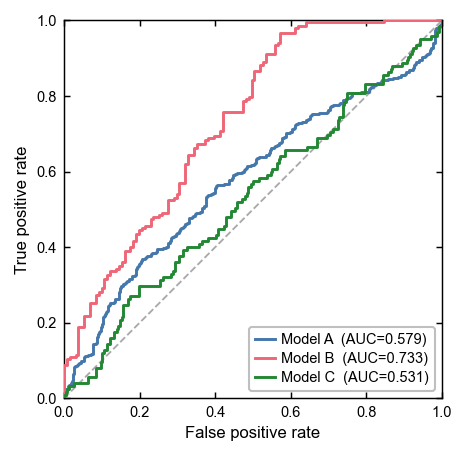

In [356]:

# ── Figure ────────────────────────────────────────────────────────────────────
# Use explicit left margin to prevent y-label clipping
fig, ax = plt.subplots(figsize=(3.15, 3.00))
fig.subplots_adjust(left=0.17, right=0.97, top=0.97, bottom=0.13)

ax.plot(fpr_A, tpr_A, color=COLOR_A, lw=1.4, zorder=3, label=f"Model A  (AUC={auc_A:.3f})")
ax.plot(fpr_B, tpr_B, color=COLOR_B, lw=1.4, zorder=3, label=f"Model B  (AUC={auc_B:.3f})")
ax.plot(fpr_C, tpr_C, color=COLOR_C, lw=1.4, zorder=3, label=f"Model C  (AUC={auc_C:.3f})")
ax.plot([0, 1], [0, 1], color=COLOR_REF, lw=0.9, ls="--", zorder=1)

# ── Axes ──────────────────────────────────────────────────────────────────────
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.set_xlabel("False positive rate", labelpad=3)
ax.set_ylabel("True positive rate", labelpad=3)
ax.set_xticks(np.arange(0, 1.1, 0.2))
ax.set_yticks(np.arange(0, 1.1, 0.2))
ax.grid(False)

# ── Legend — placed OUTSIDE the plot area, below the axes ────────────────────
# This prevents any overlap with the curves regardless of AUC values

legend = ax.legend(
    loc="lower right",
    borderaxespad=0.5,
    labelspacing=0.35,
    handletextpad=0.4,
    handlelength=1.4,
    fontsize=7,
    framealpha=1.0,
    edgecolor="0.75",
)

# ── Save ──────────────────────────────────────────────────────────────────────
# EPS: best for OUP production (vector, fonts embedded via ps.fonttype=42)
plt.savefig(os.path.join(fig_path, "figure4.eps"), bbox_inches="tight")

# PDF: vector backup, also fully acceptable
plt.savefig(os.path.join(fig_path, "figure4.pdf"), bbox_inches="tight")


plt.show()

# 4. Compare Models at Patient-level

In [357]:
test_metadata.groupby('LEAP_ID')['Response'].max().value_counts()

Response
Non-Responder    3
Responder        1
Name: count, dtype: int64

In [358]:
test_metadata['Response'].value_counts()

Response
Non-Responder    464
Responder        340
Name: count, dtype: int64

In [359]:
#patient_level_auc
model_results = {}

In [360]:
model_results['A'] = patient_level_predictions(
    results=test_metadata,
    patient_actual=sample_metadata.Response,
    thresh=0.5
)

model_results['D'] = patient_level_predictions(
    results=test_metadata,
    patient_actual=sample_metadata.Response,
    thresh=0.5,
    suffix='_imgfeat'
)

KeyError: 'probs_imgfeat'

In [ ]:
all_metrics=[]

for model_name, patient_df in model_results.items():
    
    m = patient_level_metrics(
        patient_df,
        model_name=model_name,
        thresh=0.5,
        agg="majority"
    )
    
    all_metrics.append(m)

metrics_df = pd.DataFrame(all_metrics)

In [ ]:
metrics_df.head()

In [ ]:
thresh = 0.8

In [ ]:
compare_patient_preds(test_metadata, sample_metadata.Response, thresh=thresh)

In [ ]:
compare_patient_preds(test_metadata, sample_metadata.Response, suffix='_imgfeat', thresh=thresh)

In [ ]:
compare_patient_preds(test_metadata, sample_metadata.Response, suffix='_allfeat', thresh=thresh)

In [ ]:
thresh = 0.5
display_pooled_patch_distrib(test_metadata.sort_values('LEAP_ID'), title="Inferred expr", thresh=thresh )

In [ ]:
thresh = 0.8
display_pooled_patch_distrib(test_metadata.sort_values('LEAP_ID'), title="Inferred expr", thresh=thresh,
                save_path=os.path.join(exp_path,f'pooled_A_{thresh}.png'))
display_pooled_patch_distrib(test_metadata.sort_values('LEAP_ID'),suffix='_imgfeat', title="Img feat only", thresh=thresh ,
                save_path=os.path.join(exp_path,f'pooled_D_{thresh}.png'))
#display_pooled_patch_distrib(test_metadata.sort_values('LEAP_ID'),suffix='_allfeat', title="Img feat + inferred expr" , thresh=thresh,
#                save_path=os.path.join(exp_path,f'pooled_E_{thresh}.png'))

# 5. Validation

In [362]:
image_names_val, feature_matrix_val = load_features_from_csv(os.path.join(feature_path,"imgfeats_validation.csv"))
img_feats_val = pd.DataFrame(feature_matrix_val, index=image_names_val)

In [363]:
#expression_file = os.path.join(root_path,'06-treatment_response','validation','inferredgenes_validation_calib.csv') 
if APPLY_CALIB:
    expr_file_val = 'expression_all_calibrated_imgfeats_validation.csv'
else:
    expr_file_val = 'expression_all_uncalibrated_imgfeats_validation.csv'

#expression_file = os.path.join(root_path,'06-treatment_response',f"inferredgenes_{leap}.csv")
print("loading from csv")
expr_val = pd.read_csv(os.path.join(tr_path,'inferred_expression',expr_file_val), index_col=0)

image_names1_val = list(expr_val.index)

loading from csv


In [364]:
assert (set(image_names_val)==set(image_names1_val))

In [365]:
patch_metadata_val = pd.DataFrame([x.replace('.png','').split('_') for x in image_names_val],
                                columns=['Slide', 'LEAP_ID', 'x', 'y'],
                                index=image_names_val)
patch_metadata_val[['x', 'y']] = patch_metadata_val[['x', 'y']].astype(int)
patch_metadata_val.loc[:, 'ROICoordinateX_downsampled'] =  (patch_metadata_val.loc[:,"x"] / DOWNSAMPLE).astype(int)#+22
patch_metadata_val.loc[:, 'ROICoordinateY_downsampled'] =  (patch_metadata_val.loc[:,"y"] / DOWNSAMPLE).astype(int)#+22

patch_metadata_val.head()

,Slide,LEAP_ID,x,y,ROICoordinateX_downsampled,ROICoordinateY_downsampled
SLIDE 10_LEAP022_12602_105730.png,SLIDE 10,LEAP022,12602,105730,3150,26432
SLIDE 10_LEAP022_13498_104834.png,SLIDE 10,LEAP022,13498,104834,3374,26208
SLIDE 10_LEAP022_14394_104834.png,SLIDE 10,LEAP022,14394,104834,3598,26208
SLIDE 10_LEAP022_14394_105730.png,SLIDE 10,LEAP022,14394,105730,3598,26432
SLIDE 10_LEAP022_17082_101250.png,SLIDE 10,LEAP022,17082,101250,4270,25312


In [366]:
DROP_LEAPS = {'LEAP007'}
drop_ind = patch_metadata_val[patch_metadata_val['LEAP_ID'].isin(DROP_LEAPS)].index
drop_ind

Index(['SLIDE 4_LEAP007_22898_40088.png', 'SLIDE 4_LEAP007_22898_42776.png',
       'SLIDE 4_LEAP007_23794_40088.png', 'SLIDE 4_LEAP007_23794_40984.png',
       'SLIDE 4_LEAP007_23794_41880.png', 'SLIDE 4_LEAP007_23794_42776.png',
       'SLIDE 4_LEAP007_24690_39192.png', 'SLIDE 4_LEAP007_24690_40984.png',
       'SLIDE 4_LEAP007_24690_41880.png', 'SLIDE 4_LEAP007_31858_20376.png',
       ...
       'SLIDE 4_LEAP007_63218_32920.png', 'SLIDE 4_LEAP007_63218_33816.png',
       'SLIDE 4_LEAP007_63218_34712.png', 'SLIDE 4_LEAP007_63218_35608.png',
       'SLIDE 4_LEAP007_63218_36504.png', 'SLIDE 4_LEAP007_63218_7832.png',
       'SLIDE 4_LEAP007_64114_32920.png', 'SLIDE 4_LEAP007_64114_33816.png',
       'SLIDE 4_LEAP007_64114_7832.png', 'SLIDE 4_LEAP007_65010_32920.png'],
      dtype='object', length=186)

In [367]:
expr_val = expr_val.drop(index=drop_ind)
patch_metadata_val = patch_metadata_val.drop(index=drop_ind)
img_feats_val = img_feats_val.drop(index=drop_ind)
#remove from feature_matrix

patch_metadata_val = patch_metadata_val.sort_index()
expr_val = expr_val.sort_index()
img_feats_val = img_feats_val.sort_index()

In [368]:
print(f"{len(patch_metadata_val['LEAP_ID'].unique())} LEAP cores for validation")

55 LEAP cores for validation


In [369]:
if ROBUST_GENES_ONLY:
    print(robust_genes)
    expr_val = expr_val[robust_genes]

['STRN_PanCK', 'CMPK1_PanCK', 'H1-0_PanCK', 'CXCL1_PanCK', 'ANXA8_PanCK', 'S100A9_PanCK', 'TAF6_PanCK', 'HSPA1B_PanCK', 'IGF2_PanCK', 'KRT17_CD45', 'ATP8A1_PanCK', 'IFI27_PanCK', 'KRT16_PanCK', 'KRT15_CD45', 'IRS4_PanCK', 'RPL12_PanCK', 'PI3_PanCK', 'ZEB1_PanCK', 'CCNB1_PanCK', 'LTF_PanCK', 'FABP7_PanCK', 'S100A7_CD45', 'STAC2_PanCK', 'TP63_PanCK', 'MMP11_CD45', 'RB1_PanCK', 'CA9_PanCK', 'APOE_CD45', 'RNF126_PanCK', 'BLNK_PanCK', 'RPS12_PanCK', 'KRT6A_CD45', 'SLC2A4RG_PanCK', 'COL1A1_CD45', 'NDOR1_CD45', 'AR_PanCK', 'EGFR_PanCK', 'MMP1_CD45', 'H3C1_PanCK', 'FTH1_PanCK', 'ALDOA_PanCK', 'ALDH1A1_PanCK', 'FDCSP_PanCK', 'PPP2R2B_CD45', 'MKI67_PanCK', 'CPB1_PanCK', 'C11orf58_PanCK', 'PTEN_PanCK', 'DMRTB1_PanCK', 'S100P_PanCK', 'PIGR_PanCK', 'KRT23_CD45', 'PIK3CA_PanCK', 'BRINP3_PanCK', 'CD274_PanCK', 'MIF_PanCK', 'BCL2_PanCK', 'SMR3A_CD45', 'CSN3_PanCK', 'KRT7_CD45', 'SNAI1_PanCK', 'ATP5MC2_PanCK', 'CCL24_CD45', 'S100A9_CD45', 'KRT5_CD45', 'TPSAB1_CD45', 'NWD2_PanCK', 'IFI6_CD45', 'BRCA2_Pa

## 5.1 A) Inferred model

In [ ]:
modelA = gs.best_estimator_

In [ ]:

X_val = expr_val.to_numpy()

In [ ]:
expr_cols_val = expr_val.columns.to_list()
assert len(expr_cols_val) == len(feature_names)

In [ ]:
for i, (a, b) in enumerate(zip(expr_cols_val, feature_names)):
    assert a == b, f"Mismatch at index {i}: {a} != {b}"
assert all(a == b for a, b in zip(expr_cols_val, feature_names)), "Lists differ positionally"

In [ ]:
thresh = 0.5

In [ ]:
y_probs_val = modelA.predict_proba(X_val)[:,1]
y_preds_val = (y_probs_val>thresh).astype(int)

## 5.2 D) Image feature model

In [ ]:
img_feats_val = img_feats_val.sort_index()
expr_val = expr_val.sort_index()
assert (img_feats_val.index == expr_val.index).all()

In [ ]:
modelD = gs_imgfeat.best_estimator_

In [ ]:
y_probs_val_imgfeat = modelD.predict_proba(img_feats_val)[:,1]
y_preds_val_imgfeat = (y_probs_val_imgfeat>thresh).astype(int)

## 5.3 Validation Metrics

In [ ]:
sample_metadata_val = pd.read_csv(os.path.join(root_path,'01-raw','metadata',"samples.csv"), index_col=0)
patch_metadata_val['Response'] = patch_metadata_val['LEAP_ID'].map(sample_metadata_val['Response'])
assert not patch_metadata_val['Response'].isna().any()

In [ ]:
labels_val = (patch_metadata_val['Response'] == 'Responder').astype(int)
y_val = labels_val.to_numpy()

In [ ]:
val_metrics =[]

In [ ]:
mets = display_metrics(y_val, y_probs_val, model_name='A', description='Inferred - Validation')
val_metrics.append(mets)
mets

In [ ]:
plot_classification_results(y_val, y_probs_val, threshold=0.5, vertical=False, title="Inferred expression - Validation",
                save_path=os.path.join(exp_path,'VALIDATION-confusionmatrix_A_0.5.png'))

In [ ]:
mets = display_metrics(y_val, y_probs_val_imgfeat, model_name='D', description='Image embeddings - Validation')
val_metrics.append(mets)
mets

In [ ]:
plot_classification_results(y_val, y_probs_val_imgfeat, threshold=0.5, vertical=False, title="Image embeddings - Validation",
                save_path=os.path.join(exp_path,'VALIDATION-confusionmatrix_D_0.5.png'))

In [ ]:
val_metrics_df = pd.concat(val_metrics, axis=0).reset_index(drop=True)
val_metrics_df.to_csv(os.path.join(exp_path, 'val_metrics.csv'))
val_metrics_df

In [ ]:
patch_metadata_val['probs'] = y_probs_val
patch_metadata_val['predicted'] = y_preds_val
patch_metadata_val['probs_imgfeat'] = y_probs_val_imgfeat
patch_metadata_val['predicted_imgfeat'] = y_preds_val_imgfeat

# 6. Visualize

In [ ]:
from openslide import OpenSlide
import matplotlib.patches as patches
from LEAPdata import get_slide_id
import PIL
import openslide
from PIL import Image

In [ ]:
# Increase the image pixel limit
PIL.Image.MAX_IMAGE_PIXELS = None  # Removes the limit entirely
SUPTITLESIZE=18
TITLESIZE=16
LABELSIZE=14
NOTESIZE=10
OME_LEVEL = 2 # should be level 1 but haven't extracted at 20x yet
DOWNSAMPLE = 2**OME_LEVEL

#leaporder = ['LEAP019','LEAP021','LEAP116','LEAP057']
leaporder = list(test_leaps)
leaporder

['LEAP021', 'LEAP019', 'LEAP003', 'LEAP001']

In [ ]:
#leaporder.remove('LEAP057')
#leaporder.remove('LEAP058')

In [ ]:
leaporder

['LEAP021', 'LEAP019', 'LEAP003', 'LEAP001']

In [ ]:

img_path = os.path.join(ext_root_path,'WSI','2-aligned','10x','cleaned')
WSI_PATH = os.path.join(ext_root_path,'WSI','0-original')
annotation_path = os.path.join(ext_root_path,'WSI','4-TreatmentResponse')

In [ ]:
all_annot_paths = glob.glob(os.path.join(annotation_path,'test','*.json'))
assert all_annot_paths, "have you plugged in the external HDD?"
all_annot_paths

['F:/01-data/LEAP\\WSI\\4-TreatmentResponse\\test\\SLIDE 10 ( 1- 17032799 2- 17033696 3- 17034809 2022-07-06 10.34.50.ndpi LEAP021.json',
 'F:/01-data/LEAP\\WSI\\4-TreatmentResponse\\test\\SLIDE 9- 1-17033996 2-17033161 - 2022-07-06 10.45.39.ndpi LEAP019.json']

In [ ]:
val_annot_paths = glob.glob(os.path.join(annotation_path,'validation','*.json'))
assert val_annot_paths, "have you plugged in the external HDD?"
val_annot_paths

['F:/01-data/LEAP\\WSI\\4-TreatmentResponse\\validation\\LEAP091 SLIDE 39 1- 18009136 2- 21002291 3-21002268  2023-03-08 09.27.23.ndpi.json',
 'F:/01-data/LEAP\\WSI\\4-TreatmentResponse\\validation\\LEAP026 SLIDE 12 1- 17035507 2- 17036104 - 2022-08-08 15.36.09.ndpi.json',
 'F:/01-data/LEAP\\WSI\\4-TreatmentResponse\\validation\\LEAP048 SLIDE 22 1-17063925 2-17037099.ndpi.json',
 'F:/01-data/LEAP\\WSI\\4-TreatmentResponse\\validation\\LEAP064 SLIDE 28 1- 17033921 2- 17033641.ndpi.json',
 'F:/01-data/LEAP\\WSI\\4-TreatmentResponse\\validation\\LEAP015 SLIDE 7- 1-17065270 2-18000628 - 2022-06-28 14.41.08.ndpi.json',
 'F:/01-data/LEAP\\WSI\\4-TreatmentResponse\\validation\\LEAP032 SLIDE 15 1- 17035379 2-17035253 - 2022-08-08 16.42.12.ndpi.json',
 'F:/01-data/LEAP\\WSI\\4-TreatmentResponse\\validation\\LEAP036 SLIDE 17 -1- 170636690 2- 17032048 3- 19000031 2022-10-19 15.11.59 LEAP.ndpi.json',
 'F:/01-data/LEAP\\WSI\\4-TreatmentResponse\\validation\\LEAP009 SLIDE 5- 1-19005859 2-19005860 3-

In [ ]:
limits = {}
#limits['LEAP019'] = ((3905,23409),(28339,68373))
#limits['LEAP021'] = ((18186,9708),(50877,63900)) #((18186,17708),(50877,63900))
limits['LEAP116'] = ((80532,30536),(103772,70595))
#limits['LEAP003'] = ((1366, 27072),(16402, 62610))
limits['LEAP058'] = ((867, 6885),(10940, 21173))
#limits['LEAP001'] = ((2875, 60033), (8801, 72557)) #((3875, 60033),(11201, 72557))
limits['LEAP024'] = ((4661, 38290),(19460, 79076))
limits['LEAP001'] = ((1875, 56433), (13201, 75757))
limits['LEAP003'] = ((1000, 34325), (16500, 60675))
limits['LEAP019'] = ((2900, 23400), (29400, 68370))
limits['LEAP021'] = ((18000, 8600), (51000, 64900))
limits['LEAP091'] = ((89645, 8408), (101521, 38002))
limits['LEAP026'] = ((3528, 31748), (20541, 76107))
limits['LEAP048'] = ((1285, 3888), (6941, 31974))
limits['LEAP064'] = ((3213, 24743), (23651, 89271))
limits['LEAP015'] = ((5720, 7339), (51509, 64316))
limits['LEAP032'] = ((3672, 30822), (20752, 67519))
limits['LEAP036'] = ((2821, 13953), (28878, 76515))
limits['LEAP009'] = ((3112, 6880), (20863, 53646))
limits['LEAP043'] = ((129523, 3187), (144947, 58308))

downsample_factor=0.2

scaled_limits = {
    k: (
        tuple(int(x * downsample_factor) for x in v[0]),  # xlim
        tuple(int(y * downsample_factor) for y in v[1])   # ylim
    )
    for k, v in limits.items()
}
#scaled_limits=limits
scaled_limits

{'LEAP116': ((16106, 6107), (20754, 14119)),
 'LEAP058': ((173, 1377), (2188, 4234)),
 'LEAP024': ((932, 7658), (3892, 15815)),
 'LEAP001': ((375, 11286), (2640, 15151)),
 'LEAP003': ((200, 6865), (3300, 12135)),
 'LEAP019': ((580, 4680), (5880, 13674)),
 'LEAP021': ((3600, 1720), (10200, 12980)),
 'LEAP091': ((17929, 1681), (20304, 7600)),
 'LEAP026': ((705, 6349), (4108, 15221)),
 'LEAP048': ((257, 777), (1388, 6394)),
 'LEAP064': ((642, 4948), (4730, 17854)),
 'LEAP015': ((1144, 1467), (10301, 12863)),
 'LEAP032': ((734, 6164), (4150, 13503)),
 'LEAP036': ((564, 2790), (5775, 15303)),
 'LEAP009': ((622, 1376), (4172, 10729)),
 'LEAP043': ((25904, 637), (28989, 11661))}

## Load H&E imgs

In [ ]:
#[20863, 53646]
# 4[144947, 58308]
58308/4

14577.0

In [ ]:
all_annot_paths

['F:/01-data/LEAP\\WSI\\4-TreatmentResponse\\test\\SLIDE 10 ( 1- 17032799 2- 17033696 3- 17034809 2022-07-06 10.34.50.ndpi LEAP021.json',
 'F:/01-data/LEAP\\WSI\\4-TreatmentResponse\\test\\SLIDE 9- 1-17033996 2-17033161 - 2022-07-06 10.45.39.ndpi LEAP019.json']

In [ ]:


heimgs = {}
use_png = True

for json_path in all_annot_paths:
    slide_name,slide_num, leap_id = extract_ids(json_path)
    print(f"starting {leap_id}")
    
    if use_png:
        #print("read png")
        
        slide_path = os.path.join(annotation_path,f"{leap_id}_{slide_num}_small-new.png")
        region = Image.open(slide_path)
        
    else:
        slide_path = os.path.join(WSI_PATH,slide_name)
        try:
            resolved_path = os.path.realpath(slide_path)
            wsi = OpenSlide(resolved_path)
        except openslide.lowlevel.OpenSlideError as e:
            err_msg = f'Failed to open WSI file {slide_path} with resolved path {resolved_path}: {e}.'
            print(err_msg)

        print(wsi.level_dimensions)

        w, h = wsi.level_dimensions[OME_LEVEL]
        print(f"w: {w} | h: {h}")

        region = wsi.read_region((0,0),OME_LEVEL,(w,h))
        print("saving")
        region.save(os.path.join(annotation_path,f"{leap_id}_{slide_num}_small-new.png"))
        
    print(region.size)
    heimgs[leap_id] = region
        

starting LEAP021
(13000, 16500)
starting LEAP019
(7500, 17500)


In [ ]:


heimgs_val = {}
use_png = True

for json_path in val_annot_paths:
    slide_name,slide_num, leap_id = extract_ids(json_path)
    print(f"starting {leap_id}")
    
    if use_png:
        #print("read png")
        
        slide_path = os.path.join(annotation_path,f"{leap_id}_{slide_num}_small-new.png")
        region = Image.open(slide_path)
        
    else:
        slide_path = os.path.join(WSI_PATH,slide_name)
        try:
            resolved_path = os.path.realpath(slide_path)
            wsi = OpenSlide(resolved_path)
        except openslide.lowlevel.OpenSlideError as e:
            err_msg = f'Failed to open WSI file {slide_path} with resolved path {resolved_path}: {e}.'
            print(err_msg)

        print(wsi.level_dimensions)

        w, h = wsi.level_dimensions[OME_LEVEL]
        print(f"w: {w} | h: {h}")

        region = wsi.read_region((0,0),OME_LEVEL,(w,h))
        print("saving")
        region.save(os.path.join(annotation_path,f"{leap_id}_{slide_num}_small-new.png"))
        
    print(region.size)
    heimgs_val[leap_id] = region
        

starting LEAP091
(27250, 10000)
starting LEAP026
(5400, 20000)
starting LEAP048
(2000, 9500)
starting LEAP064
(10000, 23000)
starting LEAP015
(13000, 20000)
starting LEAP032
(6000, 18000)
starting LEAP036
(9000, 21000)
starting LEAP009
(6500, 15000)
starting LEAP043
(38000, 16000)


In [ ]:
import json 

annotations = {}

for json_path in val_annot_paths:
    #print(json_path)
    slide_name,slide_num, leap_id = extract_ids(json_path)
    with open(json_path) as json_file:
        j = json.load(json_file)
        for a in j:
            c = a['properties']['classification']['name']
            geometry = a['geometry']['type']
            coordinates = a['geometry']['coordinates']
            if geometry == "Polygon":
                for a2 in coordinates:
                    points = [[int(i[0]), int(i[1])] for i in a2]
                    annotations= points

    #print(annotations)
    #print(min(annotations))
    #print(max(annotations))   
    print(f"limits['{leap_id}'] = ({tuple(min(annotations))}, {tuple(max(annotations))})")    


limits['LEAP091'] = ((89645, 8408), (101521, 38002))
limits['LEAP026'] = ((3528, 31748), (20541, 76107))
limits['LEAP048'] = ((1285, 3888), (6941, 31974))
limits['LEAP064'] = ((3213, 24743), (23651, 89271))
limits['LEAP015'] = ((5720, 7339), (51509, 64316))
limits['LEAP032'] = ((3672, 30822), (20752, 67519))
limits['LEAP036'] = ((2821, 13953), (28878, 76515))
limits['LEAP009'] = ((3112, 6880), (20863, 53646))
limits['LEAP043'] = ((129523, 3187), (144947, 58308))


In [ ]:
test_metadata['x'] = test_metadata['x'].astype(int)
test_metadata['y'] = test_metadata['y'].astype(int)
test_metadata.loc[:, 'ROICoordinateX_downsampled'] =  (test_metadata["x"] / DOWNSAMPLE).astype(int)+22
test_metadata.loc[:, 'ROICoordinateY_downsampled'] =  (test_metadata["y"] / DOWNSAMPLE).astype(int)+22
test_metadata.loc[:, 'scatter_x'] = test_metadata.loc[:, 'ROICoordinateX_downsampled']*0.2
test_metadata.loc[:, 'scatter_y'] = test_metadata.loc[:, 'ROICoordinateY_downsampled']*0.2

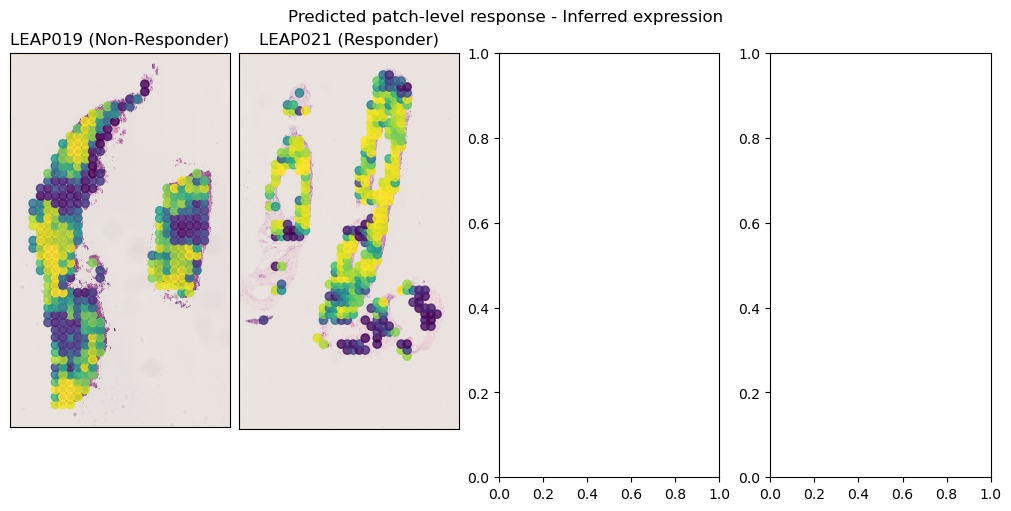

In [ ]:
#display_preds_subplots
leap_order = ['LEAP019', 'LEAP021',  'LEAP116']
leap_order = ['LEAP001', 'LEAP003',  'LEAP019', 'LEAP021']
leap_order = ['LEAP019', 'LEAP021']
thresh = 0.5

fig, axes = plt.subplots( 1, 4, figsize=(10,5), constrained_layout=True)
for ax in axes:
    #ax.set_aspect("equal")
    ax.set_anchor("N")   # 🔑 top-align

for i, leap in enumerate(leap_order):
    xlims = tuple([lim[0]/4 for lim in limits[leap]])
    ylims = tuple([lim[1]/4 for lim in limits[leap]])
    #print(f"{leap}: {abs(xlims[0]-xlims[1])} | {abs(ylims[0]-ylims[1])}")
    meta_tmp = test_metadata[test_metadata['LEAP_ID'] ==leap]

    axes[i] = display_preds_subplots(heimgs[leap],meta_tmp, 
                meta_tmp['probs'], xlim=xlims, ylim=ylims, threshold=thresh,
                title=f"{leap} ({sample_metadata.loc[leap,'Response']})", ax=axes[i], probs=True)
plt.suptitle('Predicted patch-level response - Inferred expression')
#plt.tight_layout()
plt.show()

In [ ]:

thresh = 0.8

fig, axes = plt.subplots( 1, len(leap_order), figsize=(10,5), constrained_layout=True)
for ax in axes:
    #ax.set_aspect("equal")
    ax.set_anchor("N")   # 🔑 top-align

for i, leap in enumerate(leap_order):
    xlims = tuple([lim[0]/4 for lim in limits[leap]])
    ylims = tuple([lim[1]/4 for lim in limits[leap]])
    #print(f"{leap}: {abs(xlims[0]-xlims[1])} | {abs(ylims[0]-ylims[1])}")
    meta_tmp = test_metadata[test_metadata['LEAP_ID'] ==leap]

    axes[i] = display_preds_subplots(heimgs[leap],meta_tmp, 
                meta_tmp['probs'], xlim=xlims, ylim=ylims, threshold=thresh,
                title=f"{leap} ({sample_metadata.loc[leap,'Response']})", ax=axes[i])
plt.suptitle('Predicted patch-level response')
#plt.tight_layout()
plt.show()

In [ ]:
test_metadata.head()


In [ ]:


fig, axes = plt.subplots( 1, 4, figsize=(10,5), constrained_layout=True)
for ax in axes:
    #ax.set_aspect("equal")
    ax.set_anchor("N")   # 🔑 top-align

for i, leap in enumerate(leap_order):
    xlims = tuple([lim[0]/4 for lim in limits[leap]])
    ylims = tuple([lim[1]/4 for lim in limits[leap]])
    #print(f"{leap}: {abs(xlims[0]-xlims[1])} | {abs(ylims[0]-ylims[1])}")
    meta_tmp = test_metadata[test_metadata['LEAP_ID'] ==leap]

    axes[i] = display_preds_subplots(heimgs[leap],meta_tmp, 
                meta_tmp['probs_imgfeat'], xlim=xlims, ylim=ylims, threshold=thresh,
                title=f"{leap} ({sample_metadata.loc[leap,'Response']})", ax=axes[i], probs=True)
plt.suptitle('Predicted patch-level response - Image embeddings')
#plt.tight_layout()
plt.show()

In [ ]:


fig, axes = plt.subplots( 1, len(leap_order), figsize=(10,5), constrained_layout=True)
for ax in axes:
    #ax.set_aspect("equal")
    ax.set_anchor("N")   # 🔑 top-align

for i, leap in enumerate(leap_order):
    xlims = tuple([lim[0]/4 for lim in limits[leap]])
    ylims = tuple([lim[1]/4 for lim in limits[leap]])
    #print(f"{leap}: {abs(xlims[0]-xlims[1])} | {abs(ylims[0]-ylims[1])}")
    meta_tmp = test_metadata[test_metadata['LEAP_ID'] ==leap]

    axes[i] = display_preds_subplots(heimgs[leap],meta_tmp, 
                meta_tmp['probs_imgfeat'], xlim=xlims, ylim=ylims, threshold=thresh,
                title=f"{leap} ({sample_metadata.loc[leap,'Response']})", ax=axes[i])
plt.suptitle('Predicted patch-level response - Image embeddings')
#plt.tight_layout()
plt.show()

## WSI with no overlay

In [ ]:
26450-24500

In [ ]:
74057+1700

((3905, 23409), (28339, 68373))

In [ ]:
limits['LEAP001'] = ((1875, 56433), (13201, 75757))
limits['LEAP003'] = ((1000, 34325), (16500, 60675))
limits['LEAP019'] = ((2900, 23400), (29400, 68370))
limits['LEAP021'] = ((18000, 8600), (51000, 64900))

In [ ]:
for k, v in sorted(limits.items()):
    print(k,v)
    w = v[1][0]-v[0][0]
    h = v[1][1]-v[0][1]
    ratio = h/w
    print(f"{k}\tw: {w} | h: {h} | ratio: {ratio:.1f}")


In [ ]:


fig, axes = plt.subplots( 1, 4, figsize=(10,5), constrained_layout=True)
for ax in axes:
    #ax.set_aspect("equal")
    ax.set_anchor("N")   # 🔑 top-align

for i, leap in enumerate(leap_order):
    title=f"{leap} ({sample_metadata.loc[leap,'Response']})"
    xlim = tuple([lim[0]/4 for lim in limits[leap]])
    ylim = tuple([lim[1]/4 for lim in limits[leap]])
    ax = axes[i]
    ax.imshow(heimgs[leap])
    ax.set_title(title)
    if xlim: ax.set_xlim(xlim)
    if ylim: ax.set_ylim(ylim)
    #ax.axis("off")
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_xlabel("")
    ax.set_ylabel("")
    
plt.suptitle('WSI')
#plt.tight_layout()
plt.show()

## Visualise validation predictions

In [ ]:
val_leaps = sorted(patch_metadata_val['LEAP_ID'].unique())
resp_leaps = sorted(patch_metadata_val.loc[patch_metadata_val['Response']=='Responder','LEAP_ID'].unique())
nonresp_leaps = sorted(patch_metadata_val.loc[patch_metadata_val['Response']=='Non-Responder','LEAP_ID'].unique())

In [ ]:
#thresh = 0.5
subset = patch_metadata_val[patch_metadata_val['LEAP_ID'].isin(resp_leaps[:10])]
display_pooled_patch_distrib(subset.sort_values('LEAP_ID'), title="Responders", thresh=thresh )


subset = patch_metadata_val[patch_metadata_val['LEAP_ID'].isin(resp_leaps[10:20])]
display_pooled_patch_distrib(subset.sort_values('LEAP_ID'), title="Responders", thresh=thresh )

subset = patch_metadata_val[patch_metadata_val['LEAP_ID'].isin(resp_leaps[20:])]
display_pooled_patch_distrib(subset.sort_values('LEAP_ID'), title="Responders", thresh=thresh )

In [ ]:
#thresh = 0.5
subset = patch_metadata_val[patch_metadata_val['LEAP_ID'].isin(nonresp_leaps[:10])]
display_pooled_patch_distrib(subset.sort_values('LEAP_ID'), title="Non Responders", thresh=thresh )


subset = patch_metadata_val[patch_metadata_val['LEAP_ID'].isin(nonresp_leaps[10:])]
display_pooled_patch_distrib(subset.sort_values('LEAP_ID'), title="Non Responders", thresh=thresh )

In [ ]:
#display_preds_subplots
leap_order = ['LEAP009', 'LEAP026',  'LEAP036', 'LEAP043'] #responders

thresh = 0.5

fig, axes = plt.subplots( 1, 4, figsize=(10,5), constrained_layout=True)
for ax in axes:
    #ax.set_aspect("equal")
    ax.set_anchor("N")   # 🔑 top-align

for i, leap in enumerate(leap_order):
    xlims = tuple([lim[0]/4 for lim in limits[leap]])
    ylims = tuple([lim[1]/4 for lim in limits[leap]])
    #print(f"{leap}: {abs(xlims[0]-xlims[1])} | {abs(ylims[0]-ylims[1])}")
    meta_tmp = patch_metadata_val[patch_metadata_val['LEAP_ID'] ==leap]

    axes[i] = display_preds_subplots(heimgs_val[leap],meta_tmp, 
                meta_tmp['probs'], xlim=xlims, ylim=ylims, threshold=thresh,
                title=f"{leap} ({sample_metadata_val.loc[leap,'Response']})", ax=axes[i], probs=True)
plt.suptitle('Predicted patch-level response - Inferred expression')
#plt.tight_layout()
plt.show()

In [ ]:
#display_preds_subplots
leap_order = ['LEAP015', 'LEAP032',  'LEAP048', 'LEAP064'] #NONresponders

thresh = 0.5

fig, axes = plt.subplots( 1, 4, figsize=(10,5), constrained_layout=True)
for ax in axes:
    #ax.set_aspect("equal")
    ax.set_anchor("N")   # 🔑 top-align

for i, leap in enumerate(leap_order):
    xlims = tuple([lim[0]/4 for lim in limits[leap]])
    ylims = tuple([lim[1]/4 for lim in limits[leap]])
    #print(f"{leap}: {abs(xlims[0]-xlims[1])} | {abs(ylims[0]-ylims[1])}")
    meta_tmp = patch_metadata_val[patch_metadata_val['LEAP_ID'] ==leap]

    axes[i] = display_preds_subplots(heimgs_val[leap],meta_tmp, 
                meta_tmp['probs'], xlim=xlims, ylim=ylims, threshold=thresh,
                title=f"{leap} ({sample_metadata_val.loc[leap,'Response']})", ax=axes[i], probs=True)
plt.suptitle('Predicted patch-level response - Inferred expression')
#plt.tight_layout()
plt.show()

In [ ]:

leap_order = ['LEAP009', 'LEAP026',  'LEAP036', 'LEAP043','LEAP015', 'LEAP032',  'LEAP048', 'LEAP064'] #NONresponders

fig, axes = plt.subplots( 2, 4, figsize=(10,10), constrained_layout=True)
axes = axes.flatten()
for ax in axes:
    #ax.set_aspect("equal")
    ax.set_anchor("N")   # 🔑 top-align

for i, leap in enumerate(leap_order):
    title=f"{leap} ({sample_metadata_val.loc[leap,'Response']})"
    xlim = tuple([lim[0]/4 for lim in limits[leap]])
    ylim = tuple([lim[1]/4 for lim in limits[leap]])
    ax = axes[i]
    ax.imshow(heimgs_val[leap])
    ax.set_title(title)
    if xlim: ax.set_xlim(xlim)
    if ylim: ax.set_ylim(ylim)
    #ax.axis("off")
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_xlabel("")
    ax.set_ylabel("")
    
plt.suptitle('WSI')
#plt.tight_layout()
plt.show()

# END